# 05. Preguntas sobre las elecciones

## Preguntas de análisis

| | Pregunta | Público |
| --- | --- | --- |
| 1 | ¿Cuántos votos se requieren para obtener una curul en el Concejo? | ciudadanía |
| 2 | ¿Qué candidatos no electos obtuvieron más votos que algunos electos? | medios |
| 3 | ¿Cómo se distribuyen los votos entre los candidatos de una lista? | campañas |
| 4 | ¿Qué listas convierten sus votos en curules con mayor eficiencia? | campañas |
| 5 | ¿Cuántos votos no obtuvieron representación y qué listas estuvieron más cerca? | ciudadanía |
| 6 | ¿Qué candidatos obtuvieron más votos en cada territorio? | público general |
| 7 | ¿Qué tan concentrado está el voto de cada concejal por territorio? | ciudadanía |
| 8 | ¿Qué territorios no lograron elegir a sus candidatos más votados? | ciudadanía |
| 9 | ¿Cuántos concejales fueron reelegidos? | medios |
| 10 | ¿Qué patrones caracterizan la elección de Alcaldía? | campañas |
| 11 | ¿En qué territorios obtuvo menor votación el ganador de la Alcaldía? | campañas |
| 12 | ¿Cómo se distribuyó la abstención en 2023? | campañas |
| 13 | ¿Qué relación hay entre la composición etaria del censo y la participación? | público general |
| 14 | ¿Cómo se distribuyen los votos entre los puestos de votación? | campañas |


In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.patheffects
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)

RAIZ = Path.cwd()
if not (RAIZ / "src").is_dir():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
ANALITICO = RAIZ / "datos" / "analitico"
CONCEJO = RAIZ / "datos" / "procesados" / "concejo"
GEO = RAIZ / "datos" / "geograficos"
FIGURAS = RAIZ / "resultados" / "figuras" / "preguntas"
FIGURAS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 185)
pd.set_option("display.max_colwidth", 46)

PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4",
          "#008300", "#4a3aa7", "#e34948"]
TRES = PALETA[:3]          # máximo validado cuando todos los pares se ven a la vez
SECUENCIAL = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
SUPERFICIE, TINTA, TINTA_2, TINTA_3 = "#fcfcfb", "#0b0b0b", "#52514e", "#8a8880"
ESTADO = {"bien": "#0ca30c", "aviso": "#fab219", "grave": "#ec835a", "critico": "#d03b3b"}
GRIS = "#c9c7bf"

mpl.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE,
    "savefig.facecolor": SUPERFICIE, "figure.dpi": 110, "savefig.dpi": 160,
    "font.size": 10, "axes.labelsize": 10, "axes.labelcolor": TINTA_2,
    "text.color": TINTA, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.edgecolor": "#d9d8d2", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#ebeae4", "grid.linewidth": 0.8,
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2.0, "lines.markersize": 6})


def marco(titulo, subtitulo=None, alto=4.2, ancho=10.0, grid="y"):
    """Figura con la rejilla en un solo eje y los títulos alineados al eje."""
    fig, ax = plt.subplots(figsize=(ancho, alto))
    ax.grid(False)
    if grid:
        ax.grid(True, axis=grid)
    ax.set_axisbelow(True)
    ax.text(0, 1.14 if subtitulo else 1.04, titulo, transform=ax.transAxes,
            ha="left", va="bottom", fontsize=12.5, fontweight="semibold", color=TINTA)
    if subtitulo:
        ax.set_title(subtitulo, loc="left", fontsize=9.5, color=TINTA_2, pad=8)
    return fig, ax


def etiqueta_barra(ax, barras, valores, fmt="{:,.0f}", fuera=False):
    lim = ax.get_xlim()[1]
    for b, v in zip(barras, valores):
        if pd.isna(v):
            continue
        w = b.get_width()
        afuera = fuera or w < lim * 0.30
        ax.text(w + lim * 0.012 if afuera else w - lim * 0.012,
                b.get_y() + b.get_height() / 2, fmt.format(v),
                va="center", ha="left" if afuera else "right", fontsize=8.5,
                color=TINTA_2 if afuera else "white", zorder=6,
                path_effects=[mpl.patheffects.withStroke(
                    linewidth=2.2,
                    foreground=SUPERFICIE if afuera else b.get_facecolor())])


def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(FIGURAS / f"{nombre}.png", bbox_inches="tight")


def leer(nombre, carpeta=None):
    return pd.read_csv((carpeta or ANALITICO) / nombre, keep_default_na=False,
                       na_values=[""])


# ---- Datos que usa todo el cuaderno ----
votos = pd.read_csv(ANALITICO / "votos_mesa.csv", dtype=str)
votos["votos"] = pd.to_numeric(votos["votos"], errors="coerce").fillna(0)
cand = leer("candidato_eleccion.csv")
part = leer("partido_eleccion.csv")
pe = leer("puesto_eleccion.csv")
terr = leer("agregado_territorio.csv")
agg = leer("agregado_eleccion.csv")
electos = {a: leer(f"electos_concejo_{a}.csv", CONCEJO) for a in (2019, 2023)}
nombres_electos = {a: set(d["candidato"].dropna().astype(str))
                   for a, d in electos.items()}

print("votos por mesa:", "{:,}".format(len(votos)), "filas")
print("candidaturas:  ", len(cand))
print("electos 2019:", len(electos[2019]), "| electos 2023:", len(electos[2023]))

votos por mesa: 302,979 filas
candidaturas:   2583
electos 2019: 17 | electos 2023: 17


# 1. ¿Cuántos votos se requieren para obtener una curul en el Concejo?

No hay una cifra fija. Las 17 curules se asignan mediante la **cifra repartidora**: se ordenan los cocientes de cada lista (votos divididos por 1, 2, 3 y sucesivos divisores) y se adjudican a los 17 cocientes más altos. El cociente número 17 establece el umbral de asignación para esa elección.

Ese umbral corresponde a la lista. Una vez asignadas sus curules, resultan electos sus candidatos más votados. Por eso, la votación individual necesaria depende también del total obtenido por la lista.

In [2]:
def cifra_repartidora(votos_por_lista, curules=17):
    """El cociente que ocupa la última curul. Artículo 263 de la Constitución."""
    cocientes = sorted((v / k for v in votos_por_lista for k in range(1, curules + 1)),
                       reverse=True)
    return cocientes[curules - 1]


resumen = []
for anio in (2019, 2023):
    p = part[(part["anio"] == anio) & (part["corporacion"] == "CONCEJO")]
    cifra = cifra_repartidora(p["votos"].tolist())
    el = electos[anio].copy()
    el["votos"] = pd.to_numeric(el["votos"])
    preferentes = el[el["votos"] > 0]["votos"]
    resumen.append({
        "anio": anio, "listas_con_votos": len(p),
        "cifra_repartidora": round(cifra),
        "electo_mas_votado": int(preferentes.max()),
        "electo_menos_votado": int(preferentes.min()),
        "mediana_electos": int(preferentes.median()),
        "curules_por_lista_cerrada": int((el["votos"] == 0).sum()),
    })
r = pd.DataFrame(resumen)
print(r.to_string(index=False))
print()
print("La curul le cuesta a la LISTA {:,} votos en 2023.".format(r.loc[1, "cifra_repartidora"]))
print("Al CANDIDATO le costó entre {:,} y {:,}.".format(
    r.loc[1, "electo_menos_votado"], r.loc[1, "electo_mas_votado"]))

 anio  listas_con_votos  cifra_repartidora  electo_mas_votado  electo_menos_votado  mediana_electos  curules_por_lista_cerrada
 2019                18               4412               2684                 1013             1701                          0
 2023                25               4042               2228                  932             1519                          1

La curul le cuesta a la LISTA 4,042 votos en 2023.
Al CANDIDATO le costó entre 932 y 2,228.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


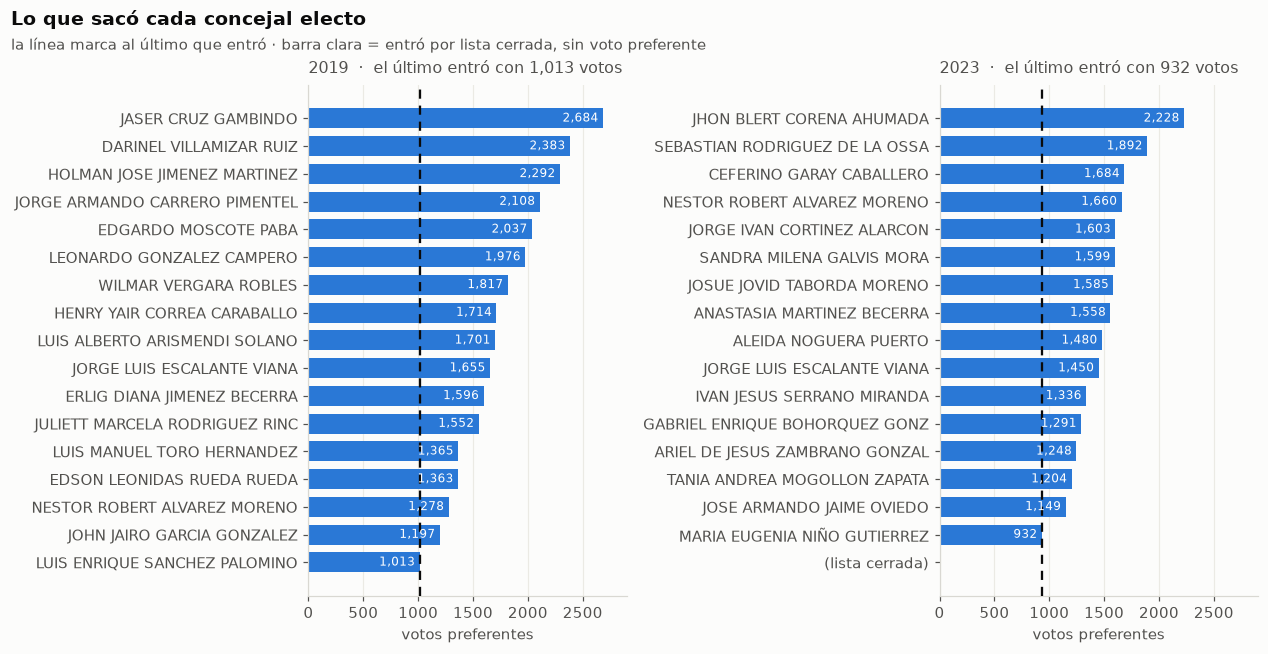

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.6, 5.6), sharex=False)
fig.text(0.01, 1.03, "Lo que sacó cada concejal electo", ha="left",
         fontsize=12.5, fontweight="semibold", color=TINTA)
fig.text(0.01, 0.99, "la línea marca al último que entró · barra clara = entró por lista cerrada, sin voto preferente",
         ha="left", fontsize=9.5, color=TINTA_2)

for ax, anio in zip(axes, (2019, 2023)):
    el = electos[anio].copy()
    el["votos"] = pd.to_numeric(el["votos"])
    el = el.sort_values("votos")
    etq = [c if isinstance(c, str) and c.strip() else "(lista cerrada)"
           for c in el["candidato"]]
    etq = [e[:30] for e in etq]
    colores = [GRIS if v == 0 else PALETA[0] for v in el["votos"]]
    ax.grid(False)
    ax.grid(True, axis="x")
    ax.set_axisbelow(True)
    b = ax.barh(etq, el["votos"], color=colores, height=0.72)
    piso = el[el["votos"] > 0]["votos"].min()
    ax.axvline(piso, color=TINTA, lw=1.5, ls=(0, (4, 3)), zorder=4)
    for bb, v in zip(b, el["votos"]):
        if v > 0:
            ax.text(v - 40, bb.get_y() + bb.get_height() / 2, "{:,.0f}".format(v),
                    va="center", ha="right", fontsize=8, color="white", zorder=6)
    ax.set_title("%d  ·  el último entró con %s votos" % (anio, "{:,}".format(int(piso))),
                 loc="left", fontsize=10.5, color=TINTA_2, pad=8)
    ax.set_xlabel("votos preferentes")
    ax.set_xlim(0, 2900)
fig.tight_layout()
fig.savefig(FIGURAS / "p01_que_saco_cada_electo.png", bbox_inches="tight")
plt.show()

En 2023, el umbral de la lista fue de **4 042 votos**. Los candidatos electos obtuvieron entre **932 y 2 228 votos**. Jhon Blert Corena Ahumada (MAIS) fue el más
votado con 2 228; María Eugenia Niño Gutiérrez (Nuevo Liberalismo) resultó electa con 932,
la mitad.

En 2019 el rango fue de **1 013** (Luis Enrique Sánchez Palomino, BUS) a **2 684** (Jaser
Cruz Gambindo, Polo Democrático).

La diferencia entre el candidato más y menos votado entre los electos fue de **2,4 veces** en 2023 y **2,6 veces** en 2019. La asignación depende de la votación de la lista y del orden de votación de sus candidatos.

**Pacto Histórico eligió mediante lista cerrada.** Los resultados por mesa no identifican al candidato electo; para determinarlo se requiere el archivo de candidaturas inscritas.

---
# 2. ¿Qué candidatos no electos superaron la votación de algunos electos?

In [4]:
def tabla_quemados(anio, tope=18):
    el = electos[anio].copy()
    el["votos"] = pd.to_numeric(el["votos"])
    piso = int(el[el["votos"] > 0]["votos"].min())
    c = cand[(cand["anio"] == anio) & (cand["corporacion"] == "CONCEJO")].copy()
    c["electo"] = c["nombre_candidato"].astype(str).isin(nombres_electos[anio])
    q = c[(~c["electo"]) & (c["votos"] > piso)].sort_values("votos", ascending=False)
    return piso, q.head(tope)


for anio in (2019, 2023):
    piso, q = tabla_quemados(anio)
    print("=" * 72)
    print("%d · el último electo entró con %s votos" % (anio, "{:,}".format(piso)))
    print("   candidatos NO electos por encima de esa cifra: %d" % len(q))
    print("=" * 72)
    t = q[["nombre_candidato", "nombre_partido", "votos"]].copy()
    t["por_encima_del_piso"] = (t["votos"] - piso).astype(int)
    print(t.to_string(index=False))
    print()

2019 · el último electo entró con 1,013 votos
   candidatos NO electos por encima de esa cifra: 18
               nombre_candidato                                     nombre_partido  votos  por_encima_del_piso
            MORGAN EGEA SANCHEZ                         PARTIDO LIBERAL COLOMBIANO   1705                  692
         DEBISON GOMEZ MARTINEZ                             PARTIDO CAMBIO RADICAL   1614                  601
            ALFONSO BAEZA ACUÑA                         PARTIDO LIBERAL COLOMBIANO   1528                  515
      FRANKLIN ANGARITA BECERRA                         PARTIDO LIBERAL COLOMBIANO   1512                  499
           HOBER TORRES ARRIETA                             PARTIDO CAMBIO RADICAL   1489                  476
   LUIS FERNANDO CALDERON MEJIA                              PARTIDO ALIANZA VERDE   1447                  434
  YEISY MARIA GONZALEZ MARTINEZ                         PARTIDO LIBERAL COLOMBIANO   1407                  394
      JHON BL

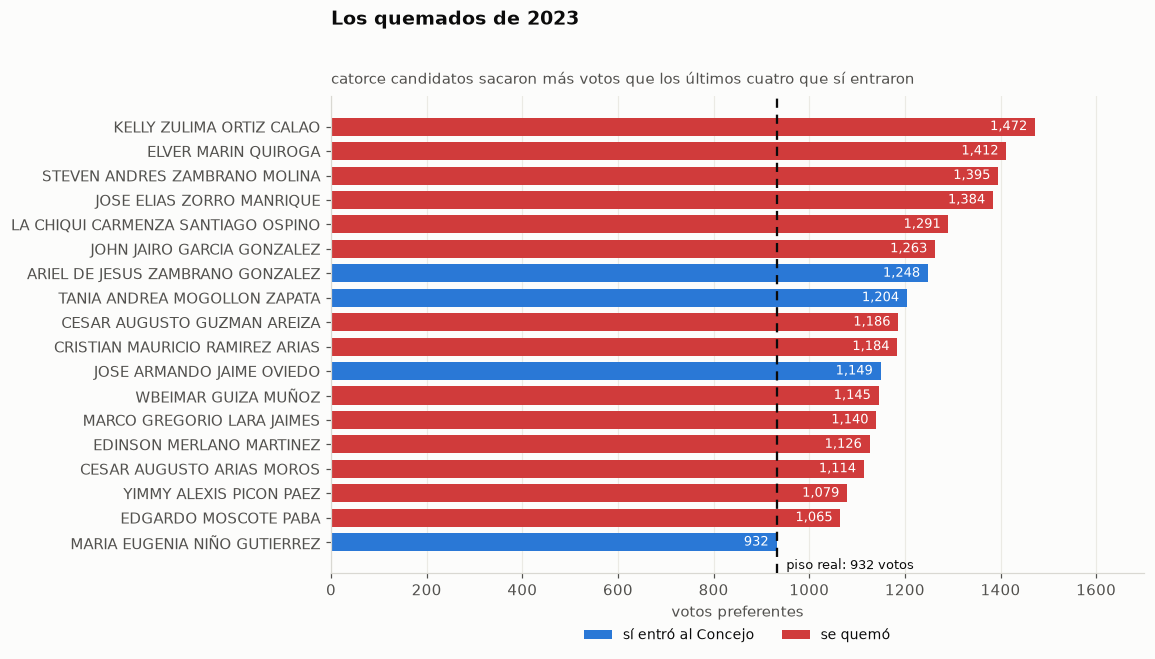

In [5]:
anio = 2023
piso, q = tabla_quemados(anio, tope=14)
el = electos[anio].copy()
el["votos"] = pd.to_numeric(el["votos"])
ult = el[el["votos"] > 0].nsmallest(4, "votos")

d = pd.concat([
    q.assign(grupo="no electo")[["nombre_candidato", "nombre_partido", "votos", "grupo"]],
    ult.rename(columns={"candidato": "nombre_candidato", "partido": "nombre_partido"})
       .assign(grupo="electo")[["nombre_candidato", "nombre_partido", "votos", "grupo"]],
]).sort_values("votos")

fig, ax = marco("Los quemados de 2023",
                "catorce candidatos sacaron más votos que los últimos cuatro que sí entraron",
                alto=6.2, ancho=10.6, grid="x")
colores = [ESTADO["critico"] if g == "no electo" else PALETA[0] for g in d["grupo"]]
etq = [n[:34] for n in d["nombre_candidato"]]
b = ax.barh(etq, d["votos"], color=colores, height=0.74)
etiqueta_barra(ax, b, d["votos"].values)
ax.axvline(piso, color=TINTA, lw=1.5, ls=(0, (4, 3)), zorder=5)
ax.text(piso + 20, -1.1, "piso real: %s votos" % "{:,}".format(piso),
        fontsize=8.5, color=TINTA)
ax.set_xlabel("votos preferentes")
ax.set_xlim(0, 1700)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=PALETA[0], label="sí entró al Concejo"),
                   Patch(facecolor=ESTADO["critico"], label="se quemó")],
          loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2)
guardar(fig, "p02_quemados_2023")
plt.show()

En 2023, **21 candidatos no electos obtuvieron más votos
que María Eugenia Niño Gutiérrez**, electa con 932 votos.

Los cinco candidatos no electos con mayor votación fueron:

| Candidato | Lista | Votos | Diferencia frente a 932 votos |
| --- | --- | ---: | ---: |
| Kelly Zulima Ortiz Calao | Vamos Unidos | 1 472 | +540 |
| Elver Marín Quiroga | Los Verídicos | 1 412 | +480 |
| Steven Andrés Zambrano Molina | Cívicos | 1 395 | +463 |
| José Elías Zorro Manrique | Agrupación Política en Marcha | 1 384 | +452 |
| La Chiqui Carmenza Santiago Ospino | Agrupación Política en Marcha | 1 291 | +359 |

En 2019 se registraron **18 casos**. Morgan Egea Sánchez (Partido Liberal) obtuvo la mayor votación entre ellos, con **1 705 votos**, por encima de la mediana de los electos (1 701).

Kelly Zulima Ortiz obtuvo 1 472 votos en Vamos Unidos, una
lista que sumó 3 033 votos y quedó a 1 009 de una curul. María Eugenia Niño obtuvo 932 votos en Nuevo Liberalismo, que sumó 8 084 y ganó dos curules. La asignación depende tanto de la votación de la lista como de la votación individual de sus candidatos.

---
# 3. ¿Cómo se distribuyen los votos entre los candidatos de una lista?

In [6]:
def perfil_lista(anio, patron):
    c = cand[(cand["anio"] == anio) & (cand["corporacion"] == "CONCEJO")
             & (cand["nombre_partido"].astype(str).str.contains(patron, na=False))].copy()
    c["electo"] = c["nombre_candidato"].astype(str).isin(nombres_electos[anio])
    c = c.sort_values("votos", ascending=False).reset_index(drop=True)
    c["pct_de_la_lista"] = (c["votos"] / c["votos"].sum() * 100).round(1)
    c["acumulado"] = c["pct_de_la_lista"].cumsum().round(1)
    return c


marcha = perfil_lista(2023, "MARCHA")
mais = perfil_lista(2023, "MAIS")

print("AGRUPACIÓN POLÍTICA EN MARCHA · 2023")
print(marcha[["nombre_candidato", "votos", "pct_de_la_lista", "acumulado",
              "electo"]].to_string(index=False))
print("\n   total de la lista: {:,} votos · {} electos · {:,} votos en no electos".format(
    int(marcha["votos"].sum()), int(marcha["electo"].sum()),
    int(marcha.loc[~marcha["electo"], "votos"].sum())))
print("\nMOVIMIENTO ALTERNATIVO INDÍGENA Y SOCIAL MAIS · 2023 (el contraste)")
print(mais[["nombre_candidato", "votos", "pct_de_la_lista", "acumulado",
            "electo"]].head(8).to_string(index=False))
print("\n   total de la lista: {:,} votos · {} electo".format(
    int(mais["votos"].sum()), int(mais["electo"].sum())))

AGRUPACIÓN POLÍTICA EN MARCHA · 2023
                  nombre_candidato  votos  pct_de_la_lista  acumulado  electo
       JORGE IVAN CORTINEZ ALARCON   1603             10.7       10.7    True
         SANDRA MILENA GALVIS MORA   1599             10.7       21.4    True
        JOSUE JOVID TABORDA MORENO   1585             10.6       32.0    True
         JOSE ELIAS ZORRO MANRIQUE   1384              9.2       41.2   False
LA CHIQUI CARMENZA SANTIAGO OSPINO   1291              8.6       49.8   False
        JOHN JAIRO GARCIA GONZALEZ   1263              8.4       58.2   False
   CRISTIAN MAURICIO RAMIREZ ARIAS   1184              7.9       66.1   False
           YIMMY ALEXIS PICON PAEZ   1079              7.2       73.3   False
       AYLIN MARIANA REYES BAQUERO   1047              7.0       80.3   False
   JHON ALEXANDER MARTINEZ GABANZO    706              4.7       85.0   False
     JAIME AUGUSTO GONZALEZ CHARRY    652              4.3       89.3   False
             WILMAR TAMARA 

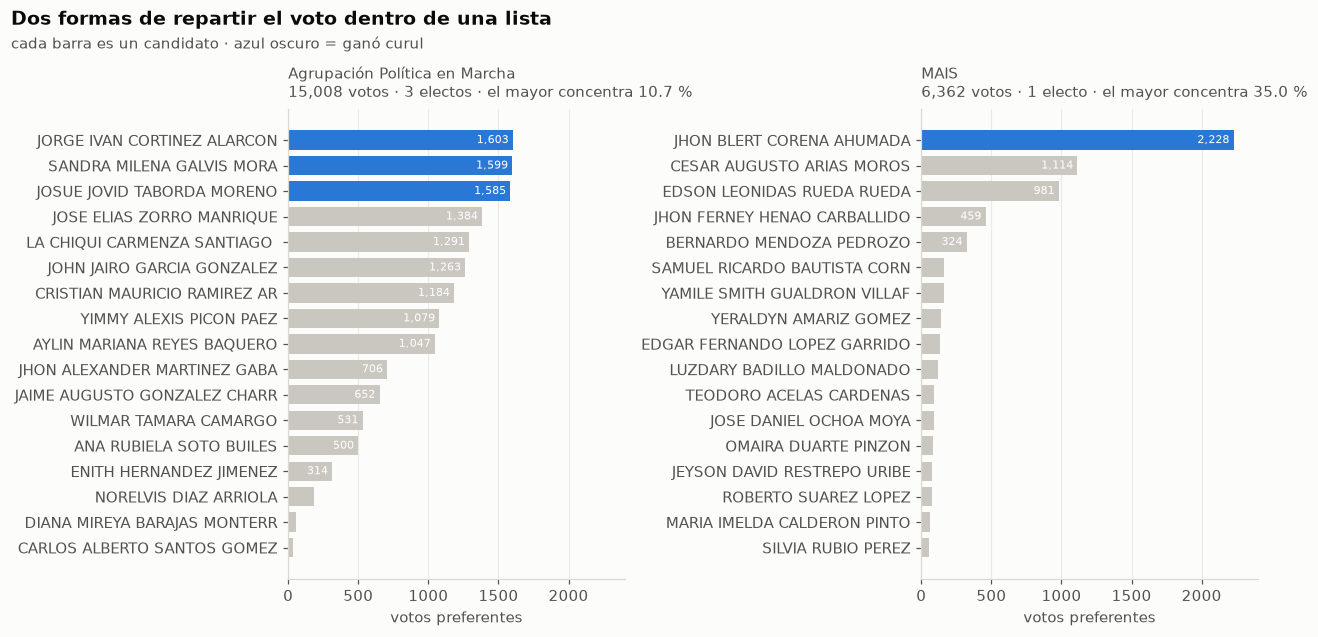

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.6, 5.4))
fig.text(0.01, 1.04, "Dos formas de repartir el voto dentro de una lista", ha="left",
         fontsize=12.5, fontweight="semibold", color=TINTA)
fig.text(0.01, 1.00, "cada barra es un candidato · azul oscuro = ganó curul",
         ha="left", fontsize=9.5, color=TINTA_2)

for ax, (d, titulo) in zip(axes, [
        (marcha, "Agrupación Política en Marcha"),
        (mais, "MAIS")]):
    d = d.sort_values("votos")
    colores = [PALETA[0] if e else GRIS for e in d["electo"]]
    ax.grid(False); ax.grid(True, axis="x"); ax.set_axisbelow(True)
    b = ax.barh([n[:28] for n in d["nombre_candidato"]], d["votos"], color=colores,
                height=0.76)
    for bb, v in zip(b, d["votos"]):
        if v >= 300:
            ax.text(v - 30, bb.get_y() + bb.get_height() / 2, "{:,.0f}".format(v),
                    va="center", ha="right", fontsize=7.5, color="white", zorder=6)
    mejor = d["votos"].max() / d["votos"].sum() * 100
    n_el = int(d["electo"].sum())
    ax.set_title("%s\n%s votos · %d %s · el mayor concentra %.1f %%"
                 % (titulo, "{:,}".format(int(d['votos'].sum())),
                    n_el, "electo" if n_el == 1 else "electos", mejor),
                 loc="left", fontsize=10, color=TINTA_2, pad=8)
    ax.set_xlabel("votos preferentes")
    ax.set_xlim(0, 2400)
fig.tight_layout()
fig.savefig(FIGURAS / "p03_canibalizacion.png", bbox_inches="tight")
plt.show()

Agrupación Política en Marcha en 2023 obtuvo la mayor votación preferente del Concejo, con votos distribuidos entre varios candidatos.

Presentó 17 candidatos, obtuvo **15 008 votos preferentes**, la mayor votación del
Concejo, y eligió **3**. Jorge Iván Cortínez Alarcón, su candidato más votado, concentró
el **10,7 %** de la votación de la lista. Los tres electos obtuvieron 1 603, 1 599 y 1 585 votos.

Otros seis candidatos superaron los mil votos:

| Candidato | Votos | Quedó a |
| --- | ---: | ---: |
| José Elías Zorro Manrique | 1 384 | 201 votos del tercer electo |
| La Chiqui Carmenza Santiago Ospino | 1 291 | 294 |
| John Jairo García González | 1 263 | 322 |
| Cristian Mauricio Ramírez Arias | 1 184 | 401 |
| Yimmy Alexis Picón Páez | 1 079 | 506 |
| Aylin Mariana Reyes Baquero | 1 047 | 538 |

En total, **10 221 votos de la lista correspondieron a candidatos no electos**, cerca de dos tercios de su votación.

En contraste, MAIS sumó 6 362 votos preferentes y eligió un candidato. Jhon Blert Corena Ahumada concentró el **35 %** de la votación de la lista, con
2 228 votos y fue **el candidato más votado de todo el Concejo**. El segundo de MAIS sacó
1 114: la mitad.

En Marcha obtuvo **3 curules** con 15 008 votos (5 003 por curul). MAIS eligió un candidato, que concentró el 35 % de los votos de su lista. Estos resultados describen la distribución de votos en 2023 y no permiten establecer qué estrategia será más efectiva en una elección futura.

---
# 4. ¿Qué listas obtuvieron más curules en relación con sus votos?

La comparación considera los votos obtenidos por cada curul. Dos listas con votaciones similares pueden obtener distinto número de curules según sus cocientes.

In [8]:
def eficiencia(anio):
    el = electos[anio].copy()
    cur = el.groupby("partido").size().rename("curules").reset_index()
    norm = lambda s: (s.astype(str).str.upper()
                      .str.replace(r"[^A-Z0-9 ]", "", regex=True).str.strip())
    cur["_n"] = norm(cur["partido"])
    p = part[(part["anio"] == anio) & (part["corporacion"] == "CONCEJO")].copy()
    p["_n"] = norm(p["nombre_partido"])
    m = p.merge(cur[["_n", "curules"]], on="_n", how="left")
    m["curules"] = m["curules"].fillna(0).astype(int)
    m["pct_votos"] = (m["votos"] / m["votos"].sum() * 100).round(2)
    m["pct_curules"] = (m["curules"] / m["curules"].sum() * 100).round(2)
    m["ventaja_en_puntos"] = (m["pct_curules"] - m["pct_votos"]).round(2)
    m["votos_por_curul"] = np.where(m["curules"] > 0,
                                    (m["votos"] / m["curules"]).round(0), np.nan)
    return m.sort_values("votos", ascending=False)


ef23 = eficiencia(2023)
ef19 = eficiencia(2019)
print("2023 · listas con curul, ordenadas por lo que les costó cada una")
con = ef23[ef23["curules"] > 0].sort_values("votos_por_curul")
print(con[["nombre_partido", "votos", "curules", "votos_por_curul", "pct_votos",
           "pct_curules", "ventaja_en_puntos"]].to_string(index=False))

2023 · listas con curul, ordenadas por lo que les costó cada una
                                 nombre_partido  votos  curules  votos_por_curul  pct_votos  pct_curules  ventaja_en_puntos
                      PARTIDO NUEVO LIBERALISMO   8084        2           4042.0       6.74        11.76               5.02
                    POR UN CAMBIO BUENO Y JUSTO   4073        1           4073.0       3.40         5.88               2.48
                                PACTO HISTORICO   4111        1           4111.0       3.43         5.88               2.45
                                 INDEPENDIENTES   9295        2           4648.0       7.76        11.76               4.00
                     PARTIDO LIBERAL COLOMBIANO  10024        2           5012.0       8.36        11.76               3.40
                  AGRUPACIÓN POLÍTICA EN MARCHA  15354        3           5118.0      12.81        17.65               4.84
                                        CIVICOS  10842        2    

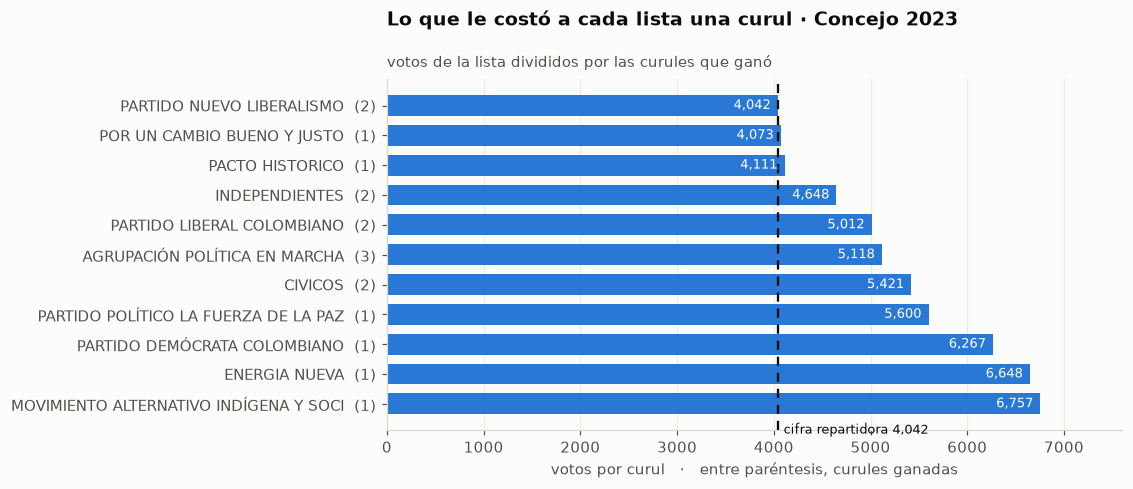

In [9]:
d = ef23[ef23["curules"] > 0].sort_values("votos_por_curul", ascending=False)
fig, ax = marco("Lo que le costó a cada lista una curul · Concejo 2023",
                "votos de la lista divididos por las curules que ganó",
                alto=4.6, ancho=10.4, grid="x")
etq = [n[:38] + ("  (%d)" % c) for n, c in zip(d["nombre_partido"], d["curules"])]
b = ax.barh(etq, d["votos_por_curul"], color=PALETA[0], height=0.7)
etiqueta_barra(ax, b, d["votos_por_curul"].values)
cifra = cifra_repartidora(ef23["votos"].tolist())
ax.axvline(cifra, color=TINTA, lw=1.5, ls=(0, (4, 3)), zorder=5)
ax.text(cifra + 60, -1.0, "cifra repartidora %s" % "{:,.0f}".format(cifra),
        fontsize=8.5, color=TINTA)
ax.set_xlabel("votos por curul   ·   entre paréntesis, curules ganadas")
ax.set_xlim(0, 7600)
guardar(fig, "p04_eficiencia_partidos")
plt.show()

En 2023, las listas electas obtuvieron entre **4 042 y 6 757 votos por curul**:

- **Partido Nuevo Liberalismo** obtuvo 2 curules con 8 084 votos, **4 042 por curul**, igual a la cifra repartidora.
- **MAIS** obtuvo una curul con 6 757 votos, un 67 % más por curul.

En 2019, Cambio Radical obtuvo 3 curules con 13 236 votos (4 412 por curul); Cívicos al 100 % obtuvo una curul con **8 641 votos**.

La variable `ventaja_en_puntos` compara la proporción de curules con la proporción de votos de cada lista. En 2023, los valores más altos fueron los de Nuevo Liberalismo (+5,0), En Marcha (+4,8) e Independientes (+4,0). Conservador-MIRA (−3,2) y AICO (−3,0) obtuvieron votos, pero no curules.

El índice de Gallagher fue **9,1 en 2023** y 7,5 en 2019, lo que indica una mayor desproporcionalidad entre votos y curules en 2023.

---
# 5. ¿Cuántos votos no obtuvieron representación?

In [10]:
filas = []
for anio in (2019, 2023):
    e = eficiencia(anio)
    cifra = cifra_repartidora(e["votos"].tolist())
    sin = e[e["curules"] == 0].copy()
    sin["le_falto"] = (cifra - sin["votos"]).round(0).astype(int)
    filas.append({"anio": anio, "listas_sin_curul": len(sin),
                  "votos_sin_representacion": int(sin["votos"].sum()),
                  "pct_del_voto_a_listas": round(sin["votos"].sum() / e["votos"].sum() * 100, 1),
                  "cifra_repartidora": round(cifra),
                  "curules_equivalentes": int(sin["votos"].sum() // cifra)})
    print("=" * 70)
    print("%d · listas sin curul y cuánto les faltó" % anio)
    print("=" * 70)
    print(sin.sort_values("votos", ascending=False)[
        ["nombre_partido", "votos", "le_falto"]].to_string(index=False))
    print()
print(pd.DataFrame(filas).to_string(index=False))

2019 · listas sin curul y cuánto les faltó
                                   nombre_partido  votos  le_falto
                       PARTIDO CENTRO DEMOCRATICO   4341        71
            BARRANCABERMEJA LIBRE HUMANA Y EN PAZ   3600       812
                   PARTIDO CONSERVADOR COLOMBIANO   3037      1375
                                      PARTIDO ADA   2372      2040
                    PARTIDO COLOMBIA JUSTA LIBRES   1122      3290
MOVIMIENTO AUTORIDADES INDIGENAS DE COLOMBIA AICO    886      3526
                           PARTIDO POLITICO  MIRA    821      3591

2023 · listas sin curul y cuánto les faltó
                                           nombre_partido  votos  le_falto
                       PARTIDO CONSERVADOR - PARTIDO MIRA   3853       189
      MOVIMIENTO AUTORIDADES INDÍGENAS DE COLOMBIA "AICO"   3644       398
                              PARTIDO COLOMBIA RENACIENTE   3412       630
                                      FUERZA CON DIGNIDAD   3134       908
  

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


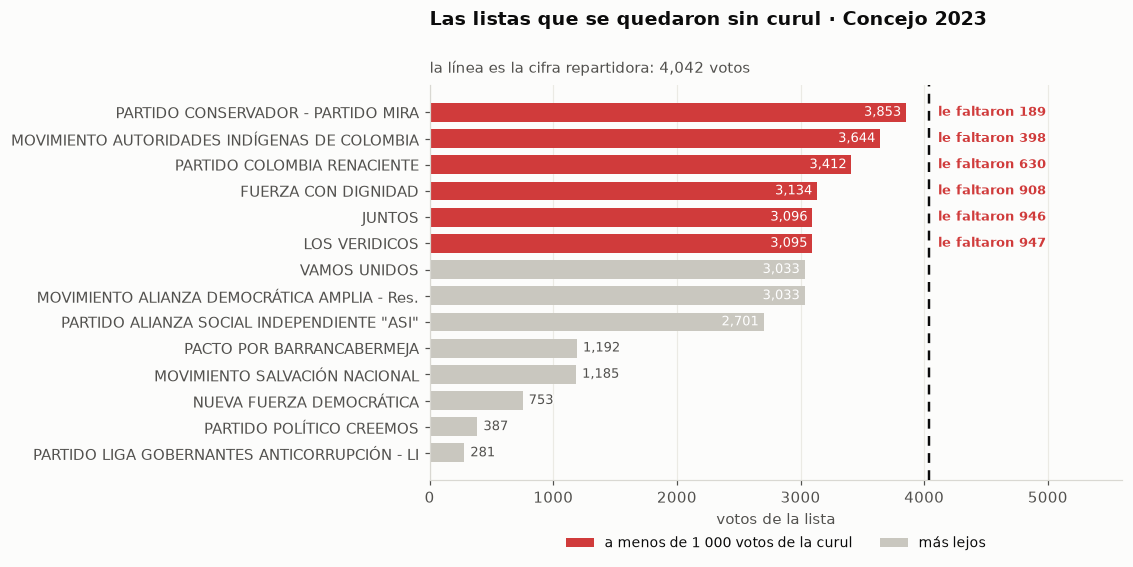

In [11]:
e = eficiencia(2023)
cifra = cifra_repartidora(e["votos"].tolist())
sin = e[e["curules"] == 0].copy()
sin["le_falto"] = (cifra - sin["votos"]).round(0)
sin = sin.sort_values("votos")

fig, ax = marco("Las listas que se quedaron sin curul · Concejo 2023",
                "la línea es la cifra repartidora: %s votos" % "{:,.0f}".format(cifra),
                alto=5.4, ancho=10.4, grid="x")
colores = [ESTADO["critico"] if f <= 1000 else GRIS for f in sin["le_falto"]]
b = ax.barh([n[:44] for n in sin["nombre_partido"]], sin["votos"], color=colores,
            height=0.72)
etiqueta_barra(ax, b, sin["votos"].values)
ax.axvline(cifra, color=TINTA, lw=1.6, ls=(0, (4, 3)), zorder=5)
for bb, v, f in zip(b, sin["votos"], sin["le_falto"]):
    if f <= 1000:
        ax.text(cifra + 70, bb.get_y() + bb.get_height() / 2,
                "le faltaron %s" % "{:,.0f}".format(f), va="center", fontsize=8.5,
                color=ESTADO["critico"], fontweight="semibold")
ax.set_xlabel("votos de la lista")
ax.set_xlim(0, 5600)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=ESTADO["critico"], label="a menos de 1 000 votos de la curul"),
                   Patch(facecolor=GRIS, label="más lejos")],
          loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2)
guardar(fig, "p05_listas_sin_curul")
plt.show()

En 2023, **el 27,4 % de los votos al Concejo (32 799 votos) correspondió a 14 listas sin curules**. En 2019 fueron 16 179 votos (14,5 %).

Las listas más cercanas a la cifra repartidora fueron:

| Lista | Votos | Votos faltantes |
| --- | ---: | ---: |
| Partido Conservador - Partido MIRA | 3 853 | **189** |
| Movimiento Autoridades Indígenas AICO | 3 644 | **398** |
| Partido Colombia Renaciente | 3 412 | 630 |
| Fuerza con Dignidad | 3 134 | 908 |
| Juntos | 3 096 | 946 |
| Los Verídicos | 3 095 | 947 |

Al Conservador-MIRA le faltaron **189 votos** para alcanzar la cifra repartidora.

En términos aritméticos, 32 799 votos equivalen a **8 curules** al umbral de 4 042 votos por curul. Ocho de las catorce listas quedaron a menos de 1 100 votos de la cifra repartidora. Esta equivalencia no implica que los votos pudieran sumarse entre listas.

La suma no indica que las listas debieran unirse ni que sus votantes hubieran apoyado una lista conjunta. Describe la relación entre votos y curules bajo la regla vigente.

---
# 6. ¿Qué candidatos obtuvieron más votos en cada territorio?

Se presenta la distribución territorial de los votos al Concejo en 2023.

In [12]:
conc23 = votos[(votos["anio"] == "2023") & (votos["corporacion"] == "CONCEJO")
               & (votos["tipo_opcion"] == "candidato") & (votos["votos"] > 0)].copy()
por_terr = conc23.groupby(["territorio", "nombre_candidato", "nombre_partido"],
                          as_index=False)["votos"].sum()
por_terr["electo"] = por_terr["nombre_candidato"].astype(str).isin(nombres_electos[2023])

print("LOS TRES MÁS VOTADOS EN CADA TERRITORIO · Concejo 2023")
print("(*) = resultó electo\n")
for t, s in por_terr.groupby("territorio"):
    if t in ("CARCEL", ""):
        continue
    top = s.nlargest(3, "votos")
    print(t)
    for _, r in top.iterrows():
        print("   %s %-36s %5d   %s" % ("*" if r["electo"] else " ",
                                        r["nombre_candidato"][:36], int(r["votos"]),
                                        str(r["nombre_partido"])[:34]))
    print()

LOS TRES MÁS VOTADOS EN CADA TERRITORIO · Concejo 2023
(*) = resultó electo

COMUNA 1
     DAVID MARTINEZ PEREZ                   458   CIVICOS
     WBEIMAR GUIZA MUÑOZ                    441   INDEPENDIENTES
   * JHON BLERT CORENA AHUMADA              356   MOVIMIENTO ALTERNATIVO INDÍGENA Y 

COMUNA 2
     JOHN JAIRO GARCIA GONZALEZ             347   AGRUPACIÓN POLÍTICA EN MARCHA
   * JORGE LUIS ESCALANTE VIANA             268   POR UN CAMBIO BUENO Y JUSTO
     CESAR AUGUSTO ARIAS MOROS              262   MOVIMIENTO ALTERNATIVO INDÍGENA Y 

COMUNA 3
   * JORGE IVAN CORTINEZ ALARCON            329   AGRUPACIÓN POLÍTICA EN MARCHA
   * JORGE LUIS ESCALANTE VIANA             291   POR UN CAMBIO BUENO Y JUSTO
   * JHON BLERT CORENA AHUMADA              290   MOVIMIENTO ALTERNATIVO INDÍGENA Y 

COMUNA 4
   * SEBASTIAN RODRIGUEZ DE LA OSSA         642   PARTIDO LIBERAL COLOMBIANO
   * JHON BLERT CORENA AHUMADA              500   MOVIMIENTO ALTERNATIVO INDÍGENA Y 
     LA CHIQUI CARMENZA SANT

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


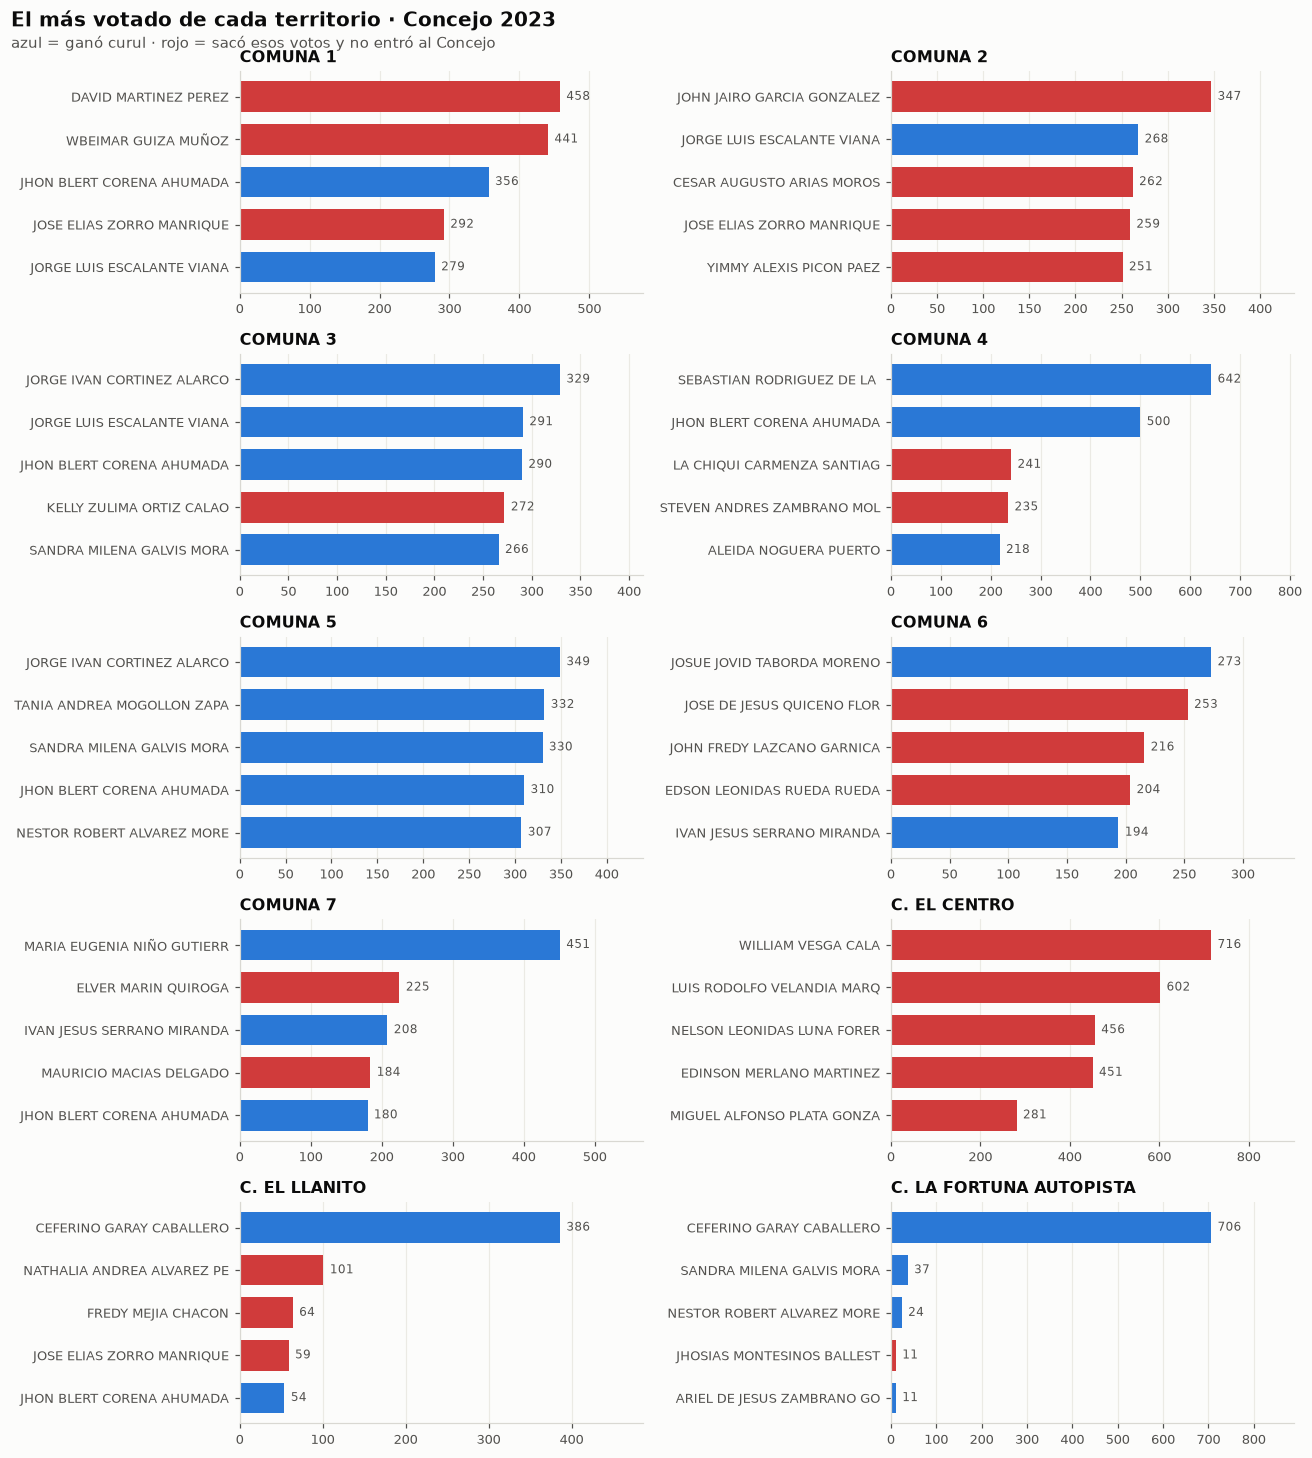

In [13]:
orden_t = ["COMUNA 1", "COMUNA 2", "COMUNA 3", "COMUNA 4", "COMUNA 5", "COMUNA 6",
           "COMUNA 7", "CORREGIMIENTO EL CENTRO", "CORREGIMIENTO EL LLANITO",
           "CORREGIMIENTO LA FORTUNA AUTOPISTA"]
fig, axes = plt.subplots(5, 2, figsize=(12.0, 13.0))
fig.text(0.01, 1.005, "El más votado de cada territorio · Concejo 2023", ha="left",
         fontsize=13, fontweight="semibold", color=TINTA)
fig.text(0.01, 0.990, "azul = ganó curul · rojo = sacó esos votos y no entró al Concejo",
         ha="left", fontsize=9.5, color=TINTA_2)

for ax, t in zip(axes.ravel(), orden_t):
    s = por_terr[por_terr["territorio"] == t].nlargest(5, "votos").sort_values("votos")
    colores = [PALETA[0] if e else ESTADO["critico"] for e in s["electo"]]
    ax.grid(False); ax.grid(True, axis="x"); ax.set_axisbelow(True)
    b = ax.barh([n[:26] for n in s["nombre_candidato"]], s["votos"], color=colores,
                height=0.72)
    for bb, v in zip(b, s["votos"]):
        ax.text(v + s["votos"].max() * 0.02, bb.get_y() + bb.get_height() / 2,
                "{:,.0f}".format(v), va="center", fontsize=8, color=TINTA_2)
    ax.set_title(t.replace("CORREGIMIENTO ", "C. "), loc="left", fontsize=10.5,
                 color=TINTA, fontweight="semibold", pad=6)
    ax.set_xlim(0, s["votos"].max() * 1.26)
    ax.tick_params(labelsize=8.5)
fig.tight_layout()
fig.savefig(FIGURAS / "p06_quien_manda_por_territorio.png", bbox_inches="tight")
plt.show()

El candidato con más votos en cada territorio en 2023:

| Territorio | Candidato | Lista | Votos | Electo |
| --- | --- | --- | ---: | --- |
| Comuna 1 | David Martínez Pérez | Cívicos | 458 | **no** |
| Comuna 2 | John Jairo García González | En Marcha | 347 | **no** |
| Comuna 3 | Jorge Iván Cortínez Alarcón | En Marcha | 329 | sí |
| Comuna 4 | Sebastián Rodríguez de la Ossa | Liberal | 642 | sí |
| Comuna 5 | Jorge Iván Cortínez Alarcón | En Marcha | 349 | sí |
| Comuna 6 | Josué Jovid Taborda Moreno | En Marcha | 273 | sí |
| Comuna 7 | María Eugenia Niño Gutiérrez | Nuevo Liberalismo | 451 | sí |
| C. El Centro | William Vesga Cala | AICO | 716 | **no** |
| C. El Llanito | Ceferino Garay Caballero | Demócrata | 386 | sí |
| C. La Fortuna | Ceferino Garay Caballero | Demócrata | 706 | sí |

El candidato más votado no resultó electo en tres territorios: comunas 1 y 2, y el corregimiento El Centro. En El Centro, ninguno de los tres candidatos con mayor votación resultó electo.

En la Comuna 7, María Eugenia Niño obtuvo 451 de sus 932 votos totales, casi la mitad. Fue la candidata electa con menor votación individual.

Ceferino Garay obtuvo la mayor votación en El Llanito, La Fortuna y Meseta de San Rafael.

# 7. ¿Qué tan concentrado está el voto de cada concejal por territorio?

In [14]:
filas = []
for n in sorted(nombres_electos[2023]):
    s = por_terr[por_terr["nombre_candidato"] == n]
    if not len(s):
        continue
    total = s["votos"].sum()
    mejor = s.loc[s["votos"].idxmax()]
    p = s["votos"] / total
    filas.append({
        "concejal": n, "lista": str(s["nombre_partido"].iloc[0]),
        "votos": int(total), "territorio_mas_fuerte": mejor["territorio"],
        "pct_alli": round(mejor["votos"] / total * 100, 1),
        "hhi_territorial": round(float((p ** 2).sum()), 3),
        "territorios_con_voto": int(len(s))}
    )
feudos = pd.DataFrame(filas).sort_values("pct_alli", ascending=False)
print(feudos.to_string(index=False))

                          concejal                                           lista  votos               territorio_mas_fuerte  pct_alli  hhi_territorial  territorios_con_voto
      MARIA EUGENIA NIÑO GUTIERREZ                       PARTIDO NUEVO LIBERALISMO    932                            COMUNA 7      48.4            0.273                    10
          CEFERINO GARAY CABALLERO                    PARTIDO DEMÓCRATA COLOMBIANO   1684  CORREGIMIENTO LA FORTUNA AUTOPISTA      41.9            0.244                    11
    SEBASTIAN RODRIGUEZ DE LA OSSA                      PARTIDO LIBERAL COLOMBIANO   1892                            COMUNA 4      33.9            0.185                    12
      TANIA ANDREA MOGOLLON ZAPATA                      PARTIDO LIBERAL COLOMBIANO   1204                            COMUNA 5      27.6            0.169                    11
         JHON BLERT CORENA AHUMADA MOVIMIENTO ALTERNATIVO INDÍGENA Y SOCIAL "MAIS"   2228                            COMUNA 4

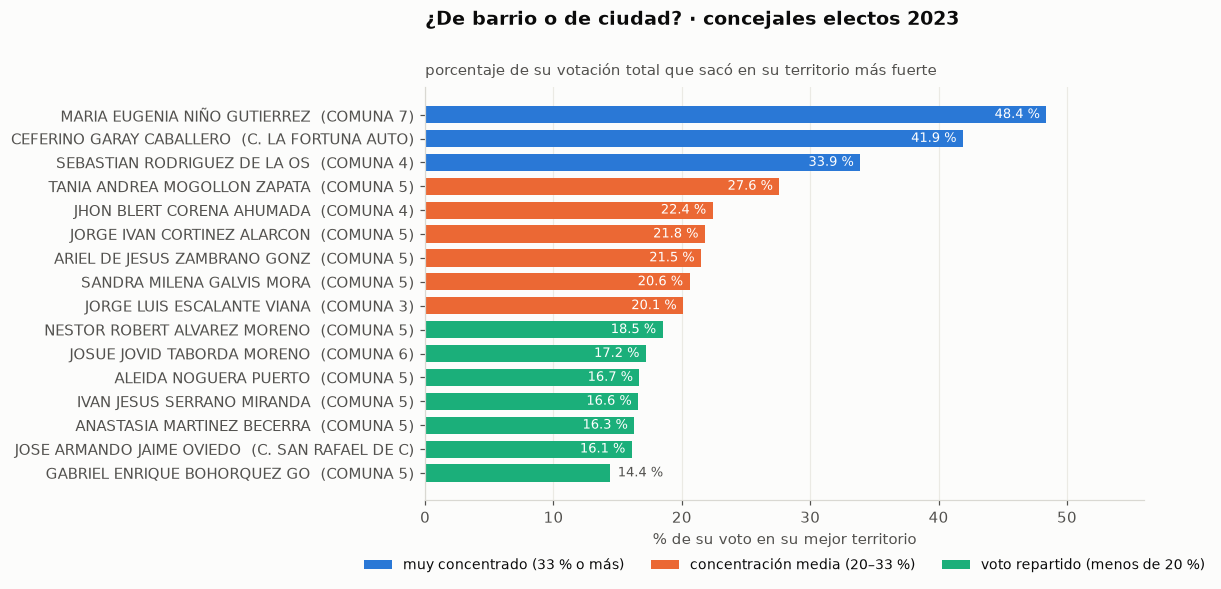

In [15]:
d = feudos.sort_values("pct_alli")
fig, ax = marco("¿De barrio o de ciudad? · concejales electos 2023",
                "porcentaje de su votación total que sacó en su territorio más fuerte",
                alto=5.6, ancho=10.6, grid="x")
# Tres colores: el máximo validado cuando todos los pares se comparan a la vez.
corte = lambda p: 0 if p >= 33 else (1 if p >= 20 else 2)
colores = [TRES[corte(p)] for p in d["pct_alli"]]
etq = ["%s  (%s)" % (n[:28], t.replace("CORREGIMIENTO ", "C. ")[:18])
       for n, t in zip(d["concejal"], d["territorio_mas_fuerte"])]
b = ax.barh(etq, d["pct_alli"], color=colores, height=0.72)
etiqueta_barra(ax, b, d["pct_alli"].values, fmt="{:.1f} %")
ax.set_xlabel("% de su voto en su mejor territorio")
ax.set_xlim(0, 56)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=TRES[0], label="muy concentrado (33 % o más)"),
                   Patch(facecolor=TRES[1], label="concentración media (20–33 %)"),
                   Patch(facecolor=TRES[2], label="voto repartido (menos de 20 %)")],
          loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=3)
guardar(fig, "p07_feudos")
plt.show()

Los concejales con mayor concentración territorial obtuvieron al menos un tercio de sus votos en un solo territorio:

| Concejal | Lista | Su territorio | % de su voto allí |
| --- | --- | --- | ---: |
| María Eugenia Niño Gutiérrez | Nuevo Liberalismo | Comuna 7 | **48,4 %** |
| Ceferino Garay Caballero | Demócrata Colombiano | C. La Fortuna | **41,9 %** |
| Sebastián Rodríguez de la Ossa | Liberal | Comuna 4 | **33,9 %** |

En otros casos, la votación se distribuyó entre varios territorios:

| Concejal | Lista | Su mejor territorio | % allí |
| --- | --- | --- | ---: |
| Gabriel Enrique Bohórquez González | Nuevo Liberalismo | Comuna 5 | 14,4 % |
| José Armando Jaime Oviedo | Independientes | C. San Rafael | 16,1 % |
| Iván Jesús Serrano Miranda | Energía Nueva | Comuna 5 | 16,6 % |
| Aleida Noguera Puerto | La Fuerza de la Paz | Comuna 5 | 16,7 % |

María Eugenia Niño resultó electa con 932 votos y obtuvo el 48,4 % de estos en la Comuna 7. Ceferino Garay obtuvo 1 684 votos y registró su mayor votación en tres corregimientos.

Jhon Blert Corena, el candidato con más votos (2 228), obtuvo el 22,4 % de su votación en su territorio de mayor apoyo.

La concentración territorial describe dónde obtuvo cada candidato sus votos. Por sí sola no permite determinar dónde hizo campaña, dónde vive ni las razones de ese patrón.

# 8. ¿Qué territorios no eligieron a sus candidatos más votados?

In [16]:
resumen_t = []
for t, s in por_terr.groupby("territorio"):
    if t in ("", "CARCEL"):
        continue
    electos_aqui = s[s["electo"]]
    top3 = s.nlargest(3, "votos")
    resumen_t.append({
        "territorio": t,
        "votos_del_territorio": int(s["votos"].sum()),
        "el_mas_votado": s.loc[s["votos"].idxmax(), "nombre_candidato"],
        "salio_electo": bool(s.loc[s["votos"].idxmax(), "electo"]),
        "electos_en_el_top_3": int(top3["electo"].sum()),
        "voto_a_electos_pct": round(electos_aqui["votos"].sum() / s["votos"].sum() * 100, 1),
    })
rt = pd.DataFrame(resumen_t).sort_values("voto_a_electos_pct")
print("QUÉ PROPORCIÓN DEL VOTO DE CADA TERRITORIO FUE A PARAR A UN ELECTO")
print(rt.to_string(index=False))

QUÉ PROPORCIÓN DEL VOTO DE CADA TERRITORIO FUE A PARAR A UN ELECTO
                         territorio  votos_del_territorio                  el_mas_votado  salio_electo  electos_en_el_top_3  voto_a_electos_pct
            CORREGIMIENTO EL CENTRO                  8286             WILLIAM VESGA CALA         False                    0                13.2
                           COMUNA 1                 16868           DAVID MARTINEZ PEREZ         False                    1                19.4
                           COMUNA 3                 17140    JORGE IVAN CORTINEZ ALARCON          True                    3                19.4
                           COMUNA 2                 13938     JOHN JAIRO GARCIA GONZALEZ         False                    1                20.3
                           COMUNA 6                  9496     JOSUE JOVID TABORDA MORENO          True                    1                20.7
                           COMUNA 7                 10713   MARIA EUG

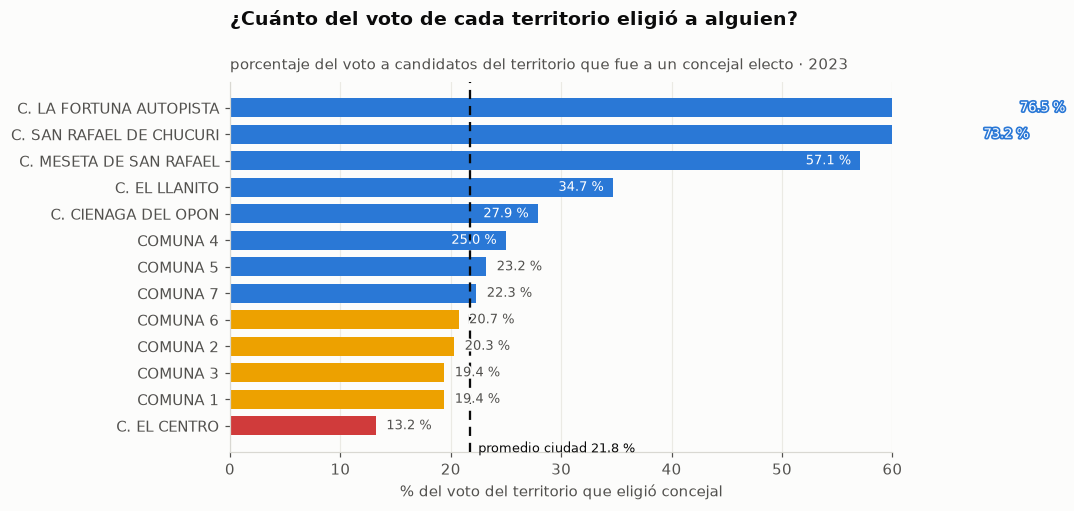

In [17]:
d = rt.sort_values("voto_a_electos_pct")
fig, ax = marco("¿Cuánto del voto de cada territorio eligió a alguien?",
                "porcentaje del voto a candidatos del territorio que fue a un concejal electo · 2023",
                alto=4.8, ancho=10.4, grid="x")
media = por_terr[por_terr["electo"]]["votos"].sum() / por_terr["votos"].sum() * 100
colores = [ESTADO["critico"] if v < media - 8 else (PALETA[0] if v >= media else PALETA[3])
           for v in d["voto_a_electos_pct"]]
b = ax.barh([t.replace("CORREGIMIENTO ", "C. ")[:32] for t in d["territorio"]],
            d["voto_a_electos_pct"], color=colores, height=0.72)
etiqueta_barra(ax, b, d["voto_a_electos_pct"].values, fmt="{:.1f} %")
ax.axvline(media, color=TINTA, lw=1.5, ls=(0, (4, 3)), zorder=5)
ax.text(media + 0.7, -1.0, "promedio ciudad %.1f %%" % media, fontsize=8.5, color=TINTA)
ax.set_xlabel("% del voto del territorio que eligió concejal")
ax.set_xlim(0, 60)
guardar(fig, "p08_voto_representado_por_territorio")
plt.show()

En el corregimiento El Centro, el territorio rural más grande, con 13 591 electores y 10 367 votos depositados, los tres candidatos con mayor votación al Concejo fueron:

| Candidato | Lista | Votos en El Centro |
| --- | --- | ---: |
| William Vesga Cala | AICO | **716** |
| Luis Rodolfo Velandia Márquez | AICO | **602** |
| Nelson Leónidas Luna Forero | La Fuerza de la Paz | **456** |

Los dos candidatos más votados no resultaron electos. Ambos pertenecían a AICO, que quedó a **398 votos** de la cifra repartidora. En El Centro obtuvieron 1 318 votos entre ambos.

En las comunas 1 y 2, el candidato con más votos tampoco resultó electo. En la Comuna 2 fue John Jairo García González, concejal en 2019.

Los concejales representan a todo el distrito. Estos resultados muestran que los candidatos más votados en esos territorios no obtuvieron una curul; no significan que dichos territorios carezcan de representación legal.

# 9. ¿Cuántos concejales fueron reelegidos?

In [18]:
norm = lambda s: (str(s).upper().replace(".", " ").replace(",", " ")
                  .replace("  ", " ").strip())
e19 = {norm(x) for x in nombres_electos[2019]}
e23 = {norm(x) for x in nombres_electos[2023]}
repiten = sorted(e19 & e23)

print("CONCEJALES ELECTOS EN 2019 Y TAMBIÉN EN 2023: %d de 17" % len(repiten))
for n in repiten:
    p19 = electos[2019][electos[2019]["candidato"].map(norm) == n]
    p23 = electos[2023][electos[2023]["candidato"].map(norm) == n]
    print("   %-34s 2019: %-34s %5s" % (n[:34], str(p19["partido"].iloc[0])[:34],
                                        int(p19["votos"].iloc[0])))
    print("   %-34s 2023: %-34s %5s" % ("", str(p23["partido"].iloc[0])[:34],
                                        int(p23["votos"].iloc[0])))

print("\nEX CONCEJALES DE 2019 QUE SE PRESENTARON EN 2023 Y NO FUERON REELEGIDOS:")
c23 = cand[(cand["anio"] == 2023) & (cand["corporacion"] == "CONCEJO")].copy()
c23["_n"] = c23["nombre_candidato"].map(norm)
perdieron = c23[c23["_n"].isin(e19 - e23)].sort_values("votos", ascending=False)
for _, r in perdieron.iterrows():
    v19 = int(electos[2019][electos[2019]["candidato"].map(norm)
                            == r["_n"]]["votos"].iloc[0])
    print("   %-34s 2019: %5d votos (electo)  ->  2023: %5d votos (%s)"
          % (r["nombre_candidato"][:34], v19, int(r["votos"]),
             "MÁS votos y perdió" if r["votos"] > v19 else "menos votos"))
print("\nRenovación del Concejo: %d de 17 curules cambiaron de persona (%.0f %%)"
      % (17 - len(repiten), (17 - len(repiten)) / 17 * 100))

CONCEJALES ELECTOS EN 2019 Y TAMBIÉN EN 2023: 2 de 17
   JORGE LUIS ESCALANTE VIANA         2019: PARTIDO CAMBIO RADICAL              1655
                                      2023: POR UN CAMBIO BUENO Y JUSTO         1450
   NESTOR ROBERT ALVAREZ MORENO       2019: CIVICOS AL 100%                     1278
                                      2023: CIVICOS                             1660

EX CONCEJALES DE 2019 QUE SE PRESENTARON EN 2023 Y NO FUERON REELEGIDOS:
   JOHN JAIRO GARCIA GONZALEZ         2019:  1197 votos (electo)  ->  2023:  1263 votos (MÁS votos y perdió)
   EDGARDO MOSCOTE PABA               2019:  2037 votos (electo)  ->  2023:  1065 votos (menos votos)
   EDSON LEONIDAS RUEDA RUEDA         2019:  1363 votos (electo)  ->  2023:   981 votos (menos votos)
   LUIS ENRIQUE SANCHEZ PALOMINO      2019:  1013 votos (electo)  ->  2023:   966 votos (menos votos)
   WILMAR VERGARA ROBLES              2019:  1817 votos (electo)  ->  2023:   722 votos (menos votos)

Renovación del

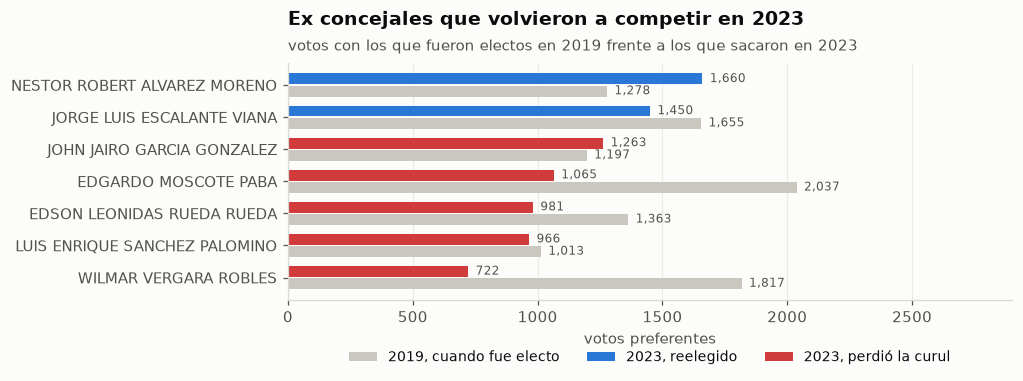

In [19]:
fig, ax = marco("Ex concejales que volvieron a competir en 2023",
                "votos con los que fueron electos en 2019 frente a los que sacaron en 2023",
                alto=3.8, ancho=9.4, grid="x")
d = []
for _, r in perdieron.iterrows():
    v19 = int(electos[2019][electos[2019]["candidato"].map(norm)
                            == r["_n"]]["votos"].iloc[0])
    d.append({"n": r["nombre_candidato"][:30], "v19": v19, "v23": int(r["votos"])})
for n in repiten:
    d.append({"n": n[:30],
              "v19": int(electos[2019][electos[2019]["candidato"].map(norm)
                                       == n]["votos"].iloc[0]),
              "v23": int(electos[2023][electos[2023]["candidato"].map(norm)
                                       == n]["votos"].iloc[0])})
d = pd.DataFrame(d).sort_values("v23")
y = np.arange(len(d))
ax.barh(y - 0.19, d["v19"], height=0.34, color=GRIS, label="2019 (fue electo)")
reelecto = [norm(n) in e23 for n in d["n"]]
ax.barh(y + 0.19, d["v23"], height=0.34,
        color=[PALETA[0] if r else ESTADO["critico"] for r in reelecto],
        label="2023")
ax.set_yticks(y)
ax.set_yticklabels(d["n"])
for i, r in d.reset_index(drop=True).iterrows():
    ax.text(r["v19"] + 30, i - 0.19, "{:,}".format(r["v19"]), va="center", fontsize=8,
            color=TINTA_2)
    ax.text(r["v23"] + 30, i + 0.19, "{:,}".format(r["v23"]), va="center", fontsize=8,
            color=TINTA_2)
ax.set_xlabel("votos preferentes")
ax.set_xlim(0, 2900)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=GRIS, label="2019, cuando fue electo"),
                   Patch(facecolor=PALETA[0], label="2023, reelegido"),
                   Patch(facecolor=ESTADO["critico"], label="2023, perdió la curul")],
          loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3)
guardar(fig, "p09_renovacion")
plt.show()

De los 17 concejales electos en 2019, **dos conservaron su curul en 2023**.

De los 17 concejales de 2019, **siete volvieron a competir en 2023** y **diez no se
presentaron**. De esos siete, solo dos conservaron la curul:

| Ex concejal | 2019 (electo) | 2023 | Resultado |
| --- | --- | --- | --- |
| **Néstor Robert Álvarez Moreno** | Cívicos al 100 %, 1 278 | Cívicos, **1 660** | reelegido, +382 |
| **Jorge Luis Escalante Viana** | Cambio Radical, 1 655 | Por un Cambio Bueno y Justo, **1 450** | reelegido, −205 |
| John Jairo García González | Tarea de Todos, 1 197 | En Marcha, **1 263** | **perdió con más votos** |
| Edgardo Moscote Paba | Liberal, 2 037 | Liberal, 1 065 | perdió, −972 |
| Edson Leonidas Rueda Rueda | MAIS, 1 363 | MAIS, 981 | perdió, −382 |
| Luis Enrique Sánchez Palomino | BUS, 1 013 | —, 966 | perdió, −47 |
| Wilmar Vergara Robles | ASI, 1 817 | —, 722 | perdió, −1 095 |

Jorge Luis Escalante Viana conservó la curul con 205 votos menos y cambió de partido. Néstor Robert Álvarez Moreno permaneció en la misma lista y obtuvo 382 votos más.

Aunque obtuvo 66 votos más que en 2019 y fue el candidato más votado de la Comuna 2, no resultó electo. En su lista, otros tres candidatos obtuvieron más votos y la lista ganó tres curules.

Wilmar Vergara Robles pasó de 1 817 a 722 votos (−60 %) y Edgardo Moscote Paba, de 2 037 a 1 065 (−48 %). Ambos eran concejales en ejercicio.

De los siete concejales de 2019 que se presentaron nuevamente, cinco no conservaron la curul. El resultado describe la renovación entre ambos periodos; no permite atribuirla a una sola causa.

---
# 10. ¿Qué patrones caracterizan la elección de Alcaldía?

In [20]:
alc = votos[(votos["corporacion"] == "ALCALDE")
            & (votos["tipo_opcion"] == "candidato")].copy()
for anio in ("2019", "2023"):
    a = alc[alc["anio"] == anio]
    t = a.groupby(["nombre_candidato", "nombre_partido"], as_index=False)["votos"].sum()
    validos = agg[(agg["anio"] == int(anio))
                  & (agg["corporacion"] == "ALCALDE")]["votos_validos"].iloc[0]
    t["pct"] = (t["votos"] / validos * 100).round(2)
    t = t.sort_values("votos", ascending=False)
    print("=" * 70)
    print("ALCALDÍA %s · %s votos válidos" % (anio, "{:,}".format(int(validos))))
    print("=" * 70)
    print(t.to_string(index=False))
    print("   margen: %s votos (%.1f puntos)\n"
          % ("{:,}".format(int(t["votos"].iloc[0] - t["votos"].iloc[1])),
             (t["votos"].iloc[0] - t["votos"].iloc[1]) / validos * 100))

ALCALDÍA 2019 · 117,626 votos válidos
                 nombre_candidato                                nombre_partido  votos   pct
          ALFONSO ELJACH MANRIQUE MOVIMIENTO ALTERNATIVO INDIGENA Y SOCIAL MAIS  55819 47.45
    JONATHAN STIVEL VASQUEZ GOMEZ                      COALICION CIVICOS AL 100  33740 28.68
CLAUDIA PATRICIA ANDRADE GONZALEZ         BARRANCABERMEJA LIBRE HUMANA Y EN PAZ  11869 10.09
    NICOLAS ANDRES CONTRERAS BAEZ                         NUEVA BARRANCABERMEJA   7835  6.66
             FREDDY PULECIO PEREZ          PARTIDO POLO DEMOCRATICO ALTERNATIVO   3698  3.14
      PABLO JESUS ARTEAGA GARRIDO        PARTIDO DE REIVINDICACION ETNICA "PRE"    718  0.61
   margen: 22,079 votos (18.8 puntos)

ALCALDÍA 2023 · 127,621 votos válidos
                 nombre_candidato                         nombre_partido  votos   pct
    JONATHAN STIVEL VASQUEZ GOMEZ           ESCRIBAMOS UN NUEVO CAPITULO  72593 56.88
       ELKIN DAVID BUENO ALTAHONA                  GRATITUD PO

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


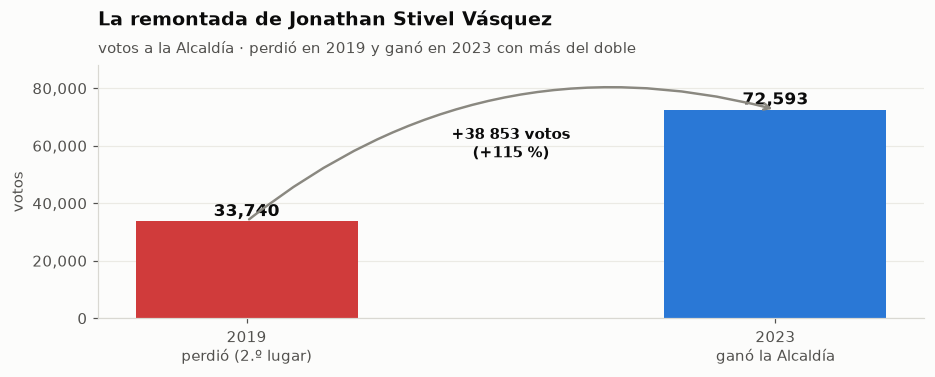

In [21]:
vas = "JONATHAN STIVEL VASQUEZ GOMEZ"
d = (alc[alc["nombre_candidato"] == vas]
     .groupby("anio", as_index=False)["votos"].sum())
otros = []
for anio in ("2019", "2023"):
    a = alc[alc["anio"] == anio]
    t = a.groupby("nombre_candidato", as_index=False)["votos"].sum()
    g = t.loc[t["votos"].idxmax()]
    otros.append({"anio": anio, "ganador": g["nombre_candidato"],
                  "votos_ganador": int(g["votos"]),
                  "votos_vasquez": int(d[d["anio"] == anio]["votos"].iloc[0])})
o = pd.DataFrame(otros)

fig, ax = marco("La remontada de Jonathan Stivel Vásquez",
                "votos a la Alcaldía · perdió en 2019 y ganó en 2023 con más del doble",
                alto=3.6, ancho=8.6, grid="y")
x = np.array([0, 1])
b = ax.bar(x, o["votos_vasquez"], width=0.42,
           color=[ESTADO["critico"], PALETA[0]])
for bb, v, g in zip(b, o["votos_vasquez"], o["ganador"]):
    ax.text(bb.get_x() + bb.get_width() / 2, v + 1800, "{:,}".format(v), ha="center",
            fontsize=11, fontweight="semibold", color=TINTA)
ax.set_xticks(x)
ax.set_xticklabels(["2019\nperdió (2.º lugar)", "2023\nganó la Alcaldía"])
ax.set_ylabel("votos")
ax.set_ylim(0, 88000)
ax.yaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("{x:,.0f}"))
ax.annotate("", xy=(1, 72593), xytext=(0, 33740),
            arrowprops=dict(arrowstyle="->", color=TINTA_3, lw=1.6,
                            connectionstyle="arc3,rad=-0.25"))
ax.text(0.5, 56000, "+38 853 votos\n(+115 %)", ha="center", fontsize=10,
        color=TINTA, fontweight="semibold")
guardar(fig, "p10_remontada_alcaldia")
plt.show()

En 2019 y 2023, los ganadores obtuvieron una proporción amplia de los votos válidos:

| Año | Ganador | Votos | % de válidos | Margen sobre el segundo |
| --- | --- | ---: | ---: | --- |
| 2019 | Alfonso Eljach Manrique (MAIS) | 55 819 | 47,5 % | 22 079 votos · 18,8 puntos |
| 2023 | Jonathan Stivel Vásquez Gómez (Escribamos un Nuevo Capítulo) | 72 593 | 56,9 % | 44 568 votos · 34,9 puntos |

Jonathan Stivel Vásquez obtuvo 33 740 votos (28,7 %) en 2019 y 72 593 (56,9 %) en 2023, un aumento de **38 853 votos (115 %)**. En 2023 se presentó bajo una marca política distinta.

El segundo lugar también cambió: en 2019 fue Vásquez; en 2023, Elkin David
Bueno Altahona con 28 025 votos (22,0 %). Claudia Patricia Andrade González compitió en
las dos y subió de 11 869 a 15 779.

En ambas elecciones se observan dos patrones:

1. El número efectivo de partidos en Alcaldía 2023 fue **2,4**, frente a **16,0** en Concejo.
2. El margen entre el ganador y el segundo lugar pasó de 18,8 a 34,9 puntos porcentuales. En 2023, el ganador obtuvo más votos que los cinco candidatos siguientes en conjunto.

Ninguna lista de Alcaldía de 2019 mantuvo el mismo nombre en 2023. Por ello, el índice de volatilidad entre ambas elecciones es 100, pero no se interpreta como cambio de preferencias: refleja los cambios de nombres y coaliciones.

---
# 11. ¿En qué territorios obtuvo menor votación el ganador de la Alcaldía?

In [22]:
a23 = alc[alc["anio"] == "2023"]
g = a23.groupby(["territorio", "nombre_candidato"], as_index=False)["votos"].sum()
tot = g.groupby("territorio")["votos"].transform("sum")
g["pct"] = (g["votos"] / tot * 100).round(1)
gan = g[g["nombre_candidato"] == vas].sort_values("pct", ascending=False)

print("VOTACIÓN DEL ALCALDE ELECTO POR TERRITORIO · 2023")
print(gan[["territorio", "votos", "pct"]].to_string(index=False))
print("\nTERRITORIOS DONDE NO GANÓ:")
for t, s in g.groupby("territorio"):
    top = s.loc[s["votos"].idxmax()]
    if top["nombre_candidato"] != vas:
        mio = s[s["nombre_candidato"] == vas]
        print("   %-36s ganó %-32s %.1f %%  (Vásquez %.1f %%)"
              % (t, top["nombre_candidato"][:32], top["pct"],
                 mio["pct"].iloc[0] if len(mio) else 0))

VOTACIÓN DEL ALCALDE ELECTO POR TERRITORIO · 2023
                         territorio  votos  pct
CORREGIMIENTO SAN RAFAEL DE CHUCURI    259 66.8
                           COMUNA 7   8072 66.7
                           COMUNA 6   7118 66.5
                           COMUNA 5  11546 61.9
                           COMUNA 3  11859 61.0
            CORREGIMIENTO EL CENTRO   5631 60.6
                           COMUNA 4   8092 56.2
                           COMUNA 1  10119 53.3
                           COMUNA 2   8287 53.1
           CORREGIMIENTO EL LLANITO   1074 50.4
                             CARCEL     24 46.2
 CORREGIMIENTO LA FORTUNA AUTOPISTA    382 34.8
     CORREGIMIENTO CIENAGA DEL OPON     59 26.3
 CORREGIMIENTO MESETA DE SAN RAFAEL     71 22.4

TERRITORIOS DONDE NO GANÓ:
   CORREGIMIENTO CIENAGA DEL OPON       ganó ELKIN DAVID BUENO ALTAHONA       45.5 %  (Vásquez 26.3 %)
   CORREGIMIENTO LA FORTUNA AUTOPISTA   ganó ELKIN DAVID BUENO ALTAHONA       46.5 %  (Vásquez 34.8

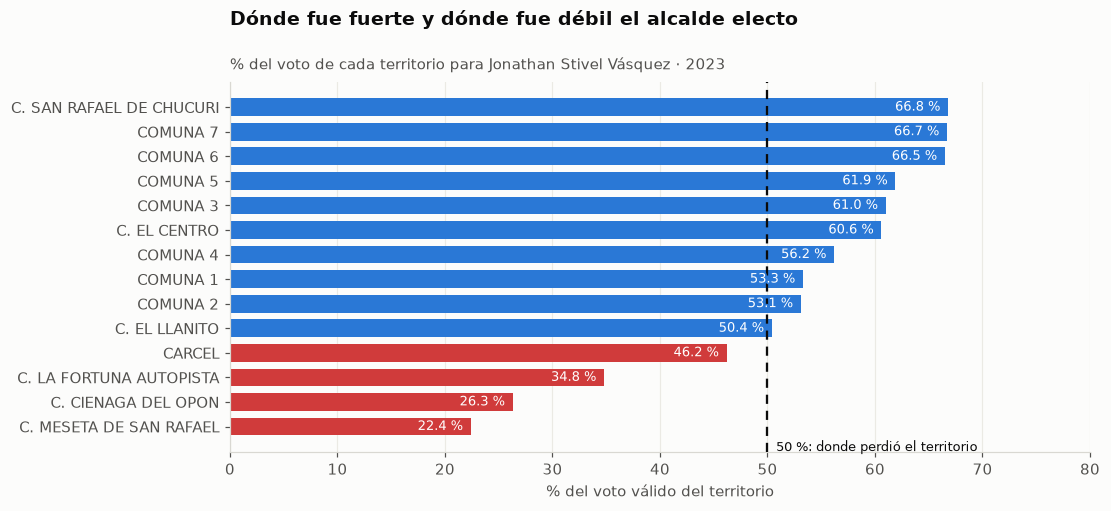

In [23]:
d = gan[gan["territorio"] != ""].sort_values("pct")
fig, ax = marco("Dónde fue fuerte y dónde fue débil el alcalde electo",
                "% del voto de cada territorio para Jonathan Stivel Vásquez · 2023",
                alto=4.8, ancho=10.2, grid="x")
colores = [ESTADO["critico"] if p < 50 else PALETA[0] for p in d["pct"]]
b = ax.barh([t.replace("CORREGIMIENTO ", "C. ")[:32] for t in d["territorio"]],
            d["pct"], color=colores, height=0.72)
etiqueta_barra(ax, b, d["pct"].values, fmt="{:.1f} %")
ax.axvline(50, color=TINTA, lw=1.5, ls=(0, (4, 3)), zorder=5)
ax.text(50.8, -1.0, "50 %: donde perdió el territorio", fontsize=8.5, color=TINTA)
ax.set_xlabel("% del voto válido del territorio")
ax.set_xlim(0, 80)
guardar(fig, "p11_mapa_del_poder")
plt.show()

Vásquez obtuvo más del 50 % de los votos en las siete comunas y en dos corregimientos.

Sus mayores porcentajes fueron en la **Comuna 7 (66,7 %)** y la **Comuna 6 (66,5 %)**; el menor porcentaje urbano fue en la **Comuna 2 (53,1 %)**.

En tres corregimientos obtuvo menos votos que Elkin David Bueno:

| Territorio | Ganó | Vásquez |
| --- | --- | ---: |
| C. Meseta de San Rafael | Elkin Bueno, 49,2 % | 22,4 % |
| C. Ciénaga del Opón | Elkin Bueno, 45,5 % | 26,3 % |
| C. La Fortuna Autopista | Elkin Bueno, 46,5 % | 34,8 % |

Estos territorios registraron entre 250 y 1 287 votos y, en conjunto, representaron menos del 1,5 % de los votos de la ciudad.

En La Fortuna, Ceferino Garay (Partido Demócrata Colombiano) obtuvo 706 votos y fue electo al Concejo. Los resultados muestran diferencias territoriales entre las votaciones para Alcaldía y Concejo.

---
# 12. ¿Cómo se distribuyó la abstención en 2023?

Además del porcentaje de abstención, se presenta el número de personas habilitadas que no votaron, por territorio.

In [24]:
t23 = terr[(terr["anio"] == 2023) & (terr["corporacion"] == "CONCEJO")].copy()
t23["no_votaron"] = (t23["potencial_electoral"] - t23["votos_depositados"]).astype(int)
t23 = t23.sort_values("no_votaron", ascending=False)
print(t23[["territorio", "ambito", "potencial_electoral", "votos_depositados",
           "participacion", "no_votaron"]].to_string(index=False))

total_no = int(t23["no_votaron"].sum())
cifra23 = 4042
print("\nPersonas habilitadas que NO votaron en 2023: {:,}".format(total_no))
print("Al precio de 2023 ({:,} votos por curul), equivalen a {} curules."
      .format(cifra23, total_no // cifra23))
print("El Concejo tiene 17.")

                         territorio   ambito  potencial_electoral  votos_depositados  participacion  no_votaron
                           COMUNA 2   urbano              26994.0              16633          61.62       10361
                           COMUNA 3   urbano              29083.0              20709          71.21        8374
                           COMUNA 1   urbano              28274.0              20116          71.15        8158
                           COMUNA 5   urbano              26564.0              19688          74.12        6876
                           COMUNA 4   urbano              21676.0              15293          70.55        6383
                           COMUNA 7   urbano              18058.0              13000          71.99        5058
                           COMUNA 6   urbano              16438.0              11423          69.49        5015
            CORREGIMIENTO EL CENTRO    rural              13591.0              10367          76.28     

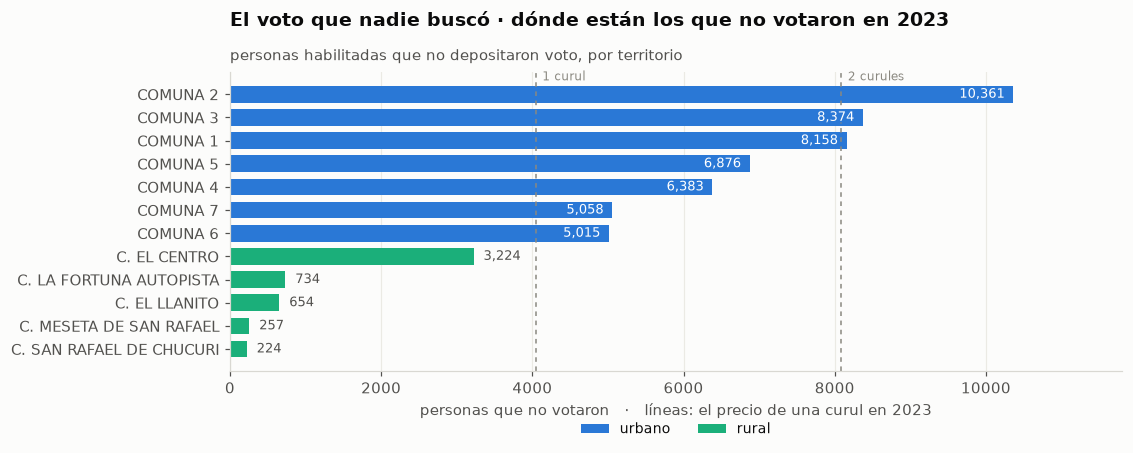

In [25]:
d = t23[t23["no_votaron"] > 200].sort_values("no_votaron")
fig, ax = marco("El voto que nadie buscó · dónde están los que no votaron en 2023",
                "personas habilitadas que no depositaron voto, por territorio",
                alto=4.4, ancho=10.4, grid="x")
colores = [PALETA[0] if a == "urbano" else PALETA[2] for a in d["ambito"]]
b = ax.barh([t.replace("CORREGIMIENTO ", "C. ")[:30] for t in d["territorio"]],
            d["no_votaron"], color=colores, height=0.72)
etiqueta_barra(ax, b, d["no_votaron"].values)
for x in (cifra23, cifra23 * 2):
    ax.axvline(x, color=TINTA_3, lw=1, ls=(0, (3, 3)), zorder=1)
ax.text(cifra23 + 90, len(d) - 0.4, "1 curul", fontsize=8, color=TINTA_3)
ax.text(cifra23 * 2 + 90, len(d) - 0.4, "2 curules", fontsize=8, color=TINTA_3)
ax.set_xlabel("personas que no votaron   ·   líneas: el precio de una curul en 2023")
ax.set_xlim(0, 11800)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=PALETA[0], label="urbano"),
                   Patch(facecolor=PALETA[2], label="rural")],
          loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
guardar(fig, "p12_voto_disponible")
plt.show()

En 2023, **55 522 personas habilitadas no votaron**. Esta cifra describe la abstención; no representa votos disponibles para una candidatura ni permite proyectar el comportamiento electoral futuro.

**Dónde están:**

| Territorio | Participación | No votaron |
| --- | ---: | ---: |
| **Comuna 2** | 61,6 % | **10 361** |
| Comuna 3 | 71,2 % | 8 374 |
| Comuna 1 | 71,2 % | 8 158 |
| Comuna 5 | 74,1 % | 6 876 |
| Comuna 4 | 70,6 % | 6 383 |
| Comuna 7 | 72,0 % | 5 058 |
| Comuna 6 | 69,5 % | 5 015 |
| C. El Centro | 76,3 % | 3 224 |

La Comuna 2 concentró casi el 19 % de la abstención del distrito y registró la menor participación.

En la Comuna 2 también se registraron el menor porcentaje urbano del alcalde electo (53,1 %) y un candidato al Concejo con mayor votación que no resultó electo. Estos datos agregados no permiten inferir cómo votarán las personas en 2027 ni por quién.

---
# 13. ¿Qué relación hay entre la composición etaria del censo y la participación?

In [26]:
c = pe[(pe["anio"] == 2023) & (pe["corporacion"] == "CONCEJO")].copy()
perfil = c.groupby("territorio").apply(lambda s: pd.Series({
    "potencial": int(s["potencial_electoral"].sum()),
    "participacion": round(s["votos_depositados"].sum()
                           / s["potencial_electoral"].sum() * 100, 1),
    "pct_18_a_30": round(s[["edad_18_20", "edad_21_25", "edad_26_30"]].sum().sum()
                         / s["potencial_electoral"].sum() * 100, 1),
    "pct_mas_de_60": round(s["edad_mas_de_60"].sum()
                           / s["potencial_electoral"].sum() * 100, 1),
    "pct_mujeres": round(s["sexo_mujeres"].sum()
                         / s["potencial_electoral"].sum() * 100, 1),
}), include_groups=False).reset_index()
perfil = perfil[perfil["territorio"] != "CARCEL"].sort_values("pct_18_a_30",
                                                             ascending=False)
print(perfil.to_string(index=False))
r_joven = np.corrcoef(perfil["pct_18_a_30"], perfil["participacion"])[0, 1]
r_mayor = np.corrcoef(perfil["pct_mas_de_60"], perfil["participacion"])[0, 1]
print("\ncorrelación entre %% de censo joven y participación: r = %.2f" % r_joven)
print("correlación entre %% de censo mayor y participación: r = %.2f" % r_mayor)

                         territorio  potencial  participacion  pct_18_a_30  pct_mas_de_60  pct_mujeres
                           COMUNA 7    18058.0           72.0         35.2           14.2         54.2
                           COMUNA 6    16438.0           69.5         33.8           16.1         53.0
 CORREGIMIENTO LA FORTUNA AUTOPISTA     2021.0           63.7         32.1           14.8         45.7
            CORREGIMIENTO EL CENTRO    13591.0           76.3         31.5           12.0         47.3
           CORREGIMIENTO EL LLANITO     3004.0           78.2         30.2           15.6         47.7
                           COMUNA 3    29083.0           71.2         27.6           14.9         55.3
                           COMUNA 5    26564.0           74.1         27.2           19.5         53.9
                           COMUNA 4    21676.0           70.6         26.1           18.5         52.2
     CORREGIMIENTO CIENAGA DEL OPON      361.0           69.3         25.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


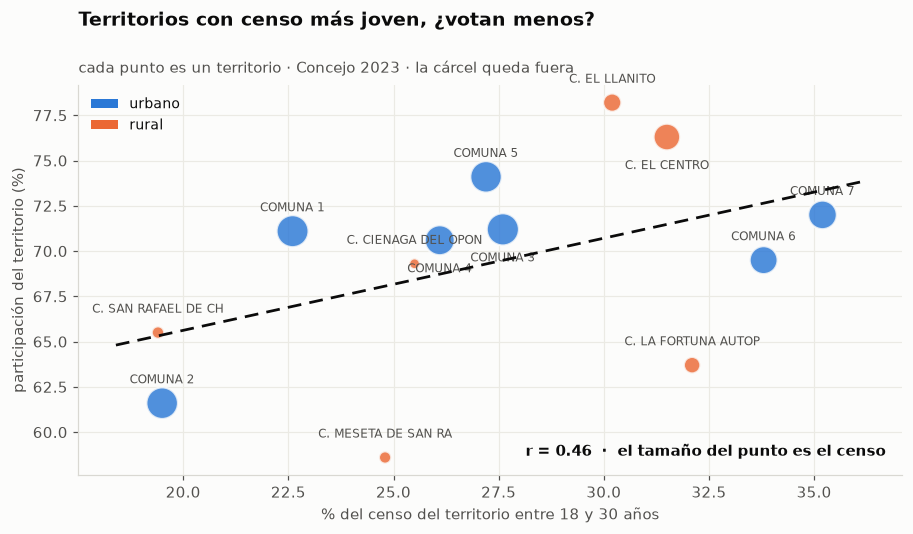

In [27]:
fig, ax = marco("Territorios con censo más joven, ¿votan menos?",
                "cada punto es un territorio · Concejo 2023 · la cárcel queda fuera",
                alto=5.0, ancho=8.4, grid=None)
ax.grid(True, axis="both")
colores = [PALETA[0] if a == "urbano" else PALETA[1]
           for a in [t23.set_index("territorio")["ambito"].get(x, "rural")
                     for x in perfil["territorio"]]]
ax.scatter(perfil["pct_18_a_30"], perfil["participacion"], s=np.sqrt(perfil["potencial"]) * 2.6,
           color=colores, alpha=0.82, edgecolor=SUPERFICIE, linewidth=1.4, zorder=3)
z = np.polyfit(perfil["pct_18_a_30"], perfil["participacion"], 1)
xs = np.linspace(perfil["pct_18_a_30"].min() - 1, perfil["pct_18_a_30"].max() + 1, 20)
ax.plot(xs, np.polyval(z, xs), color=TINTA, lw=1.8, ls=(0, (5, 3)), zorder=4)
# Las etiquetas se empujan arriba o abajo cuando dos puntos quedan muy cerca:
# sin esto, Comuna 4 y Ciénaga del Opón se pisan.
colocadas = []
for _, r in perfil.sort_values("pct_18_a_30").iterrows():
    etq = r["territorio"].replace("CORREGIMIENTO ", "C. ")
    arriba = True
    for px, py in colocadas:
        if abs(r["pct_18_a_30"] - px) < 2.2 and abs(r["participacion"] - py) < 2.4:
            arriba = False
            break
    ax.annotate(etq[:19], (r["pct_18_a_30"], r["participacion"]),
                textcoords="offset points", xytext=(0, 13 if arriba else -21),
                ha="center", fontsize=8, color=TINTA_2)
    colocadas.append((r["pct_18_a_30"], r["participacion"]))
ax.set_xlabel("% del censo del territorio entre 18 y 30 años")
ax.set_ylabel("participación del territorio (%)")
ax.text(0.98, 0.05, "r = %.2f  ·  el tamaño del punto es el censo" % r_joven,
        transform=ax.transAxes, ha="right", fontsize=9.5, color=TINTA,
        fontweight="semibold")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=PALETA[0], label="urbano"),
                   Patch(facecolor=PALETA[1], label="rural")], loc="upper left")
guardar(fig, "p13_jovenes_y_participacion")
plt.show()

En los territorios analizados, una mayor proporción de personas de 18 a 30 años en el censo se asocia con una participación algo mayor. La relación es moderada:

| Territorio | % censo de 18 a 30 años | Participación |
| --- | ---: | ---: |
| Comuna 7 | **35,2 %** | 72,0 % |
| Comuna 6 | 33,8 % | 69,5 % |
| C. La Fortuna | 32,1 % | 63,7 % |
| C. El Centro | 31,5 % | **76,3 %** |
| C. El Llanito | 30,2 % | **78,2 %** |
| Comuna 3 | 27,6 % | 71,2 % |
| Comuna 1 | 22,6 % | 71,1 % |
| **Comuna 2** | **19,5 %** | **61,6 %** |

La correlación entre los 13 territorios, **sin la cárcel**, es **r = 0,46**. La relación no implica que las personas jóvenes voten más. Por ejemplo, La Fortuna tiene un 32,1 % de población censada de 18 a 30 años y una participación de 63,7 %.

> ### Efecto de la zona 98
>
> Al incluir la cárcel, la correlación aumenta de **0,46 a 0,74**. Este puesto tiene 149 electores, un 11,4 % de personas jóvenes en el censo y una participación de 37,6 %.
>
> La cárcel es un puesto real, pero no es comparable con una comuna. Está identificada con `marca_ambito_especial` y se excluye de esta comparación.

> ### Alcance de la comparación
>
> La asociación se observa entre territorios, no entre individuos. Los datos no registran la edad de quienes votaron, solo el total de votos por puesto.
>
> No es posible determinar si la relación se debe a la edad u otras características de los territorios. Atribuir a las personas una asociación observada en datos agregados constituye una falacia ecológica.

---
# 14. ¿Cómo se distribuyen los votos entre los puestos de votación?

In [28]:
c = pe[(pe["anio"] == 2023) & (pe["corporacion"] == "CONCEJO")].copy()
c = c.sort_values("votos_depositados", ascending=False).reset_index(drop=True)
c["acumulado_pct"] = (c["votos_depositados"].cumsum()
                      / c["votos_depositados"].sum() * 100).round(1)
n50 = int((c["acumulado_pct"] <= 50).sum()) + 1
n80 = int((c["acumulado_pct"] <= 80).sum()) + 1
print("LOS 15 PUESTOS CON MÁS VOTOS · Concejo 2023")
print(c.head(15)[["puesto", "territorio", "potencial_electoral", "votos_depositados",
                  "participacion", "acumulado_pct"]].to_string(index=False))
print("\n%d puestos de %d concentran el 50 %% del voto." % (n50, len(c)))
print("%d puestos de %d concentran el 80 %% del voto." % (n80, len(c)))

LOS 15 PUESTOS CON MÁS VOTOS · Concejo 2023
                            puesto              territorio  potencial_electoral  votos_depositados  participacion  acumulado_pct
                 COL CAMILO TORRES                COMUNA 6               8577.0               5579          65.05            4.2
               COLEGIO EL CASTILLO                COMUNA 4               7435.0               5389          72.48            8.3
COL BLANCA DURAN DE PADILLA SEDE A CORREGIMIENTO EL CENTRO               6971.0               5193          74.49           12.2
                  COLEGIO INFANTAS                COMUNA 2               6143.0               4247          69.14           15.5
        COL TEC DE COMERCIO SEDE B                COMUNA 3               5844.0               4186          71.63           18.6
                      COL INTECOBA                COMUNA 1               5553.0               4176          75.20           21.8
         COLEGIO DIVINO NIÑO JESUS                COM

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


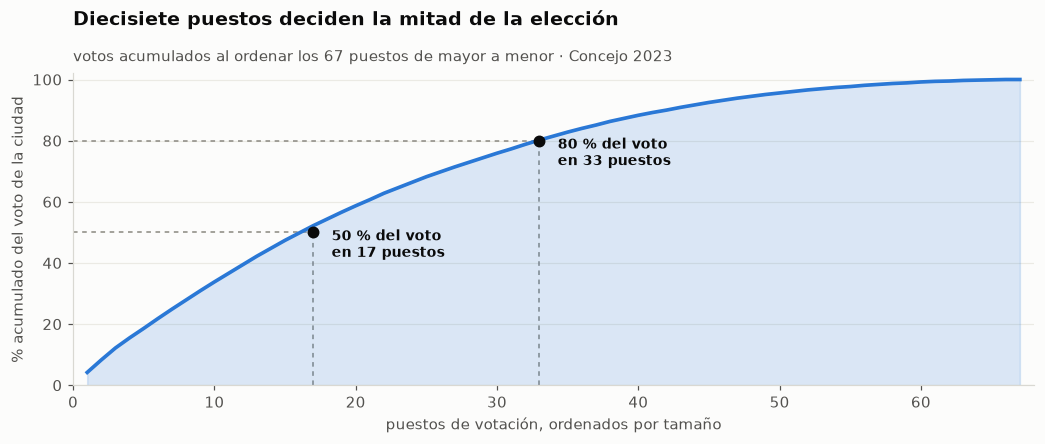

In [29]:
fig, ax = marco("Diecisiete puestos deciden la mitad de la elección",
                "votos acumulados al ordenar los 67 puestos de mayor a menor · Concejo 2023",
                alto=4.2, ancho=9.6, grid="y")
x = np.arange(1, len(c) + 1)
ax.fill_between(x, c["acumulado_pct"], color=PALETA[0], alpha=0.16, zorder=2)
ax.plot(x, c["acumulado_pct"], color=PALETA[0], lw=2.4, zorder=3)
for n, pct, txt in ((n50, 50, "50 %% del voto\nen %d puestos" % n50),
                    (n80, 80, "80 %% del voto\nen %d puestos" % n80)):
    ax.plot([n, n], [0, pct], color=TINTA_3, lw=1, ls=(0, (3, 3)), zorder=1)
    ax.plot([0, n], [pct, pct], color=TINTA_3, lw=1, ls=(0, (3, 3)), zorder=1)
    ax.scatter([n], [pct], s=46, color=TINTA, zorder=5)
    ax.annotate(txt, (n, pct), textcoords="offset points", xytext=(12, -16),
                fontsize=9, color=TINTA, fontweight="semibold")
ax.set_xlabel("puestos de votación, ordenados por tamaño")
ax.set_ylabel("% acumulado del voto de la ciudad")
ax.set_xlim(0, len(c) + 1)
ax.set_ylim(0, 102)
guardar(fig, "p14_puestos_que_deciden")
plt.show()

En 2023, **17 de los 67 puestos concentraron la mitad de los votos y 33 concentraron el 80 %**.

Los cinco mayores:

| Puesto | Territorio | Votos | Participación |
| --- | --- | ---: | ---: |
| Col. Camilo Torres | Comuna 6 | 5 579 | 65,1 % |
| Colegio El Castillo | Comuna 4 | 5 389 | 72,5 % |
| Col. Blanca Durán de Padilla sede A | C. El Centro | 5 193 | 74,5 % |
| Colegio Infantas | Comuna 2 | 4 247 | 69,1 % |
| Col. Técnico de Comercio sede B | Comuna 3 | 4 186 | 71,6 % |

Dos de estos cinco puestos registraron una participación inferior al promedio de la ciudad (70,4 %): Col. Camilo Torres (65,1 %) y Colegio Infantas (69,1 %). En Camilo Torres, cerca de 3 000 personas habilitadas no votaron.

La correlación de participación entre 2019 y 2023 es **r = 0,80** para los puestos cuya identidad se verificó. Los puestos con menor participación en un año tienden a mantener una posición similar en el otro.

La concentración de votos permite identificar los puestos que reúnen a más electores. La abstención por puesto describe cuántas personas habilitadas no votaron, pero no permite asumir que votarán en una elección futura.